# Non-pregnant anemia prevalence and DALYs averted by fortification

We take a "multiplication model" approach here, shifting continuous hemoglobin (as estimated
by GBD) and seeing what impact that has on anemia.

It's important to note that we directly use hemoglobin estimates, which are the first step
of the GBD anemia estimation pipeline. The risks and causes that are related to anemia are
all calculated downstream from this.

In [1]:
import pathlib
import pandas as pd, numpy as np
import warnings
from vivarium_gbd_access.shared_functions import get_ids
from lsff_utils import config_utils, paths
from lsff_utils import gbd_data
from lsff_utils.hemoglobin_distribution import hemoglobin_cdf_from_mean_sd

from tqdm.notebook import tqdm

In [2]:
pd.set_option("display.max_columns", 30)

In [3]:
warnings.simplefilter(action="ignore", category=pd.errors.PerformanceWarning)

In [4]:
location = "ethiopia"
vehicle = "salt"

In [5]:
# Parameters
location = "ethiopia"
vehicle = "wheat"


In [6]:
intervention_scenarios = config_utils.get_intervention_scenarios(location, vehicle)
intervention_scenarios

['intervention']

## Setup and scenarios

In [7]:
# GBD estimation year and draw set every pull below uses. Owned by gbd_data;
# shown here so a run's output records what it was built against.
gbd_data.most_recent_year(), len(gbd_data.DRAWS)

(2023, 250)

In [8]:
effective_coverage_baseline = pd.read_csv(
    f"../0100_data_prep/results/folate/{vehicle}/baseline_fortification/effective_coverage/{location}.csv"
)
assert (effective_coverage_baseline.vehicle_name == vehicle).all()
effective_coverage_baseline = effective_coverage_baseline.drop(columns=["vehicle_name"])
effective_coverage_baseline

,wealth_quintile,value
0,1,0.095256
1,2,0.095256
2,3,0.095256
3,4,0.095256
4,5,0.095256


In [9]:
def expand(df):
    for col in sorted(list(set(df.columns) - {"value"})):
        if df[col].isnull().any():
            df = pd.concat(
                [
                    df[df[col].notnull()],
                    *[
                        df[df[col].isnull()].assign(**{col: value})
                        for value in df[df[col].notnull()][col].unique()
                    ],
                ]
            )

    return df

In [10]:
for col, fill_value in [("age_start", 0), ("age_end", 125)]:
    if col not in effective_coverage_baseline.columns:
        effective_coverage_baseline[col] = fill_value
    else:
        effective_coverage_baseline[col] = effective_coverage_baseline[col].fillna(
            fill_value
        )

In [11]:
effective_coverage_baseline = expand(effective_coverage_baseline)
effective_coverage_baseline

,wealth_quintile,value,age_start,age_end
0,1,0.095256,0,125
1,2,0.095256,0,125
2,3,0.095256,0,125
3,4,0.095256,0,125
4,5,0.095256,0,125


In [12]:
effective_coverage_intervention = pd.concat(
    [
        pd.read_csv(
            f"../0100_data_prep/results/folate/{vehicle}/{intervention_scenario}/intervention_fortification/effective_coverage/{location}.csv"
        ).assign(scenario=intervention_scenario)
        for intervention_scenario in intervention_scenarios
    ]
)
assert (effective_coverage_intervention.vehicle_name == vehicle).all()
effective_coverage_intervention = effective_coverage_intervention.drop(
    columns=["vehicle_name"]
)
effective_coverage_intervention

,wealth_quintile,sex,value,scenario
0,1,Female,0.25392,intervention
1,1,Male,0.25392,intervention
2,2,Female,0.25392,intervention
3,2,Male,0.25392,intervention
4,3,Female,0.25392,intervention
5,3,Male,0.25392,intervention
6,4,Female,0.25392,intervention
7,4,Male,0.25392,intervention
8,5,Female,0.25392,intervention
9,5,Male,0.25392,intervention


In [13]:
for col, fill_value in [("age_start", 0), ("age_end", 125)]:
    if col not in effective_coverage_intervention.columns:
        effective_coverage_intervention[col] = fill_value
    else:
        effective_coverage_intervention[col] = effective_coverage_intervention[
            col
        ].fillna(fill_value)

In [14]:
effective_coverage_intervention = expand(effective_coverage_intervention)
effective_coverage_intervention

,wealth_quintile,sex,value,scenario,age_start,age_end
0,1,Female,0.25392,intervention,0,125
1,1,Male,0.25392,intervention,0,125
2,2,Female,0.25392,intervention,0,125
3,2,Male,0.25392,intervention,0,125
4,3,Female,0.25392,intervention,0,125
5,3,Male,0.25392,intervention,0,125
6,4,Female,0.25392,intervention,0,125
7,4,Male,0.25392,intervention,0,125
8,5,Female,0.25392,intervention,0,125
9,5,Male,0.25392,intervention,0,125


In [15]:
population = pd.read_csv(
    f"../0100_data_prep/results/population/stratified/{location}.csv"
)

In [16]:
non_pregnant_pop = population.pipe(lambda df: df[df.pregnant == "not_pregnant"]).drop(
    columns="pregnant"
)
non_pregnant_pop = non_pregnant_pop.set_index(
    [c for c in non_pregnant_pop.columns if c != "value"]
).value
non_pregnant_pop

sex     age_start  age_end     wealth_quintile
Female  0.0        0.019178    1                  8110.649607
                               2                  7372.711095
                               3                  6970.098109
                               4                  6250.761973
                               5                  5010.316721
                                                     ...     
Male    95.0       125.000000  1                  1459.535125
                               2                  1527.072977
                               3                  1585.027440
                               4                  1677.097974
                               5                  1469.804071
Name: value, Length: 250, dtype: float64

In [17]:
population.set_index(["sex", "age_start", "age_end"]).loc[
    ("Female", 25, 30)
].value.sum()

np.float64(4867631.407035154)

In [18]:
non_pregnant_pop.loc[("Female", 25, 30)][1]

np.float64(592418.4734924453)

In [19]:
non_pregnant_pop.loc[("Female", 25, 30)].sum()

np.float64(3845516.1503933785)

In [20]:
population_age_groups = (
    non_pregnant_pop.reset_index()[["age_start", "age_end"]]
    .drop_duplicates()
    .sort_values("age_start")
)
population_age_groups

,age_start,age_end
0,0.000000,0.019178
5,0.019178,0.076712
10,0.076712,0.500000
15,0.500000,1.000000
20,1.000000,2.000000
25,2.000000,5.000000
30,5.000000,10.000000
35,10.000000,15.000000
40,15.000000,20.000000
45,20.000000,25.000000


In [21]:
def map_to_population_age_groups(df):
    result = (
        population_age_groups.merge(df, how="cross", suffixes=("", "_orig"))
        .pipe(
            lambda df: df[
                (df.age_end <= df.age_end_orig) & (df.age_start >= df.age_start_orig)
            ]
        )
        .drop(columns=["age_start_orig", "age_end_orig"])
    )
    return result

In [22]:
effective_coverage_baseline = (
    map_to_population_age_groups(effective_coverage_baseline)
    .set_index([c for c in effective_coverage_baseline.columns if c != "value"])
    .value
)
effective_coverage_intervention = (
    map_to_population_age_groups(effective_coverage_intervention)
    .set_index([c for c in effective_coverage_intervention.columns if c != "value"])
    .value
)

In [23]:
if "sex" not in effective_coverage_baseline.index.names:
    # Assume does not vary
    effective_coverage_baseline = pd.concat(
        [
            effective_coverage_baseline.reset_index()
            .assign(sex="Female")
            .set_index(["wealth_quintile", "sex", "age_start", "age_end"])
            .value,
            effective_coverage_baseline.reset_index()
            .assign(sex="Male")
            .set_index(["wealth_quintile", "sex", "age_start", "age_end"])
            .value,
        ]
    )

In [24]:
effective_coverage_baseline = (
    effective_coverage_baseline.reset_index()
    .set_index(["sex", "age_start", "age_end", "wealth_quintile"])
    .value
)

In [25]:
if "sex" not in effective_coverage_intervention.index.names:
    # Assume does not vary
    effective_coverage_intervention = pd.concat(
        [
            effective_coverage_intervention.reset_index()
            .assign(sex="Female")
            .set_index(["sex", "age_start", "age_end", "wealth_quintile"])
            .value,
            effective_coverage_intervention.reset_index()
            .assign(sex="Male")
            .set_index(["sex", "age_start", "age_end", "wealth_quintile"])
            .value,
        ]
    )

In [26]:
effective_coverage_intervention = (
    effective_coverage_intervention.reset_index()
    # TODO: Make this clearer. This is just reordering.
    .set_index(["sex", "age_start", "age_end", "wealth_quintile", "scenario"]).value
)

In [27]:
example_sex = "Female"
example_age_start = 25
example_age_end = 30
example_wealth_quintile = 1
example_scenario = effective_coverage_intervention.index.get_level_values("scenario")[0]
example_tuple = (
    example_sex,
    example_age_start,
    example_age_end,
    example_wealth_quintile,
)

In [28]:
effective_coverage_baseline.loc[example_tuple]

np.float64(0.09525600000000001)

In [29]:
effective_coverage_intervention.loc[example_tuple]

scenario
intervention    0.25392
Name: value, dtype: float64

## Pull GBD hemoglobin distributions

In [30]:
me_ids = {
    "hemoglobin_mean": 10487,
    "hemoglobin_sd": 10488,
}
me_release_id = 33

# Verify the MEIDs against get_ids
meids_df = get_ids('modelable_entity')
assert (
    meids_df.loc[
        meids_df['modelable_entity_id'] == me_ids["hemoglobin_mean"],
        'modelable_entity_name'].squeeze()
        == 'Mean Hemoglobin (g/L, elevation adjusted) - Custom')
assert (
    meids_df.loc[
        meids_df['modelable_entity_id'] == me_ids["hemoglobin_sd"],
        'modelable_entity_name'].squeeze()
        == 'Standard Deviation of Hemoglobin (g/L, survey elevation adjusted)')


2026-11-11 00:13:38.920 | INFO     | vivarium_gbd_access._remote.dispatch:dispatch:147 - Shared functions call: get_ids('modelable_entity')


2026-11-11 00:13:42.637 | DEBUG    | vivarium_gbd_access._remote.dispatch:dispatch:186 - GBD worker ran pandas 1.5.3; this environment has 3.1.1.


In [31]:
hgb_mean = gbd_data.pull_modelable_entity_draws(
    me_ids["hemoglobin_mean"], location, release_id=me_release_id
)
hgb_mean

draw_0      draw_1      draw_2      draw_3  \
sex    age_start age_end                                                      
Female 0.000000  0.019178    143.463660  133.438981  137.817702  140.751165   
       0.019178  0.076712    127.157885  118.272590  122.153635  124.753687   
       0.076712  0.500000    104.567007   98.658189  100.623566  102.026136   
       0.500000  1.000000    101.512766   96.112224   96.666323   97.490405   
       1.000000  2.000000    102.531121   97.380264   97.930160   98.329523   
       2.000000  5.000000    108.113275  103.741427  104.693009  104.917360   
       5.000000  10.000000   120.418798  112.004404  115.679761  118.142016   
       10.000000 15.000000   131.529621  122.338846  126.353323  129.042766   
       15.000000 20.000000   130.285680  127.147313  129.181485  129.706618   
       20.000000 25.000000   129.484581  126.072553  127.956876  128.583304   
       25.000000 30.000000   128.646166  125.133411  127.088330  128.146499   
       30.000000 35.000000   128.435591  124.697454  126.546555  127.229348   
       35.000000 40.000000   129.185924  124.290353  125.570866  125.633089   
       40.000000 45.000000   129.353514  124.273065  125.556411  125.409870   
       45.000000 50.000000   129.309758  124.466563  125.867364  126.299976   
       50.000000 55.000000   133.096924  123.796632  127.858945  130.580435   
       55.000000 60.000000   134.008851  124.644838  128.734984  131.475120   
       60.000000 65.000000   134.617598  125.211048  129.319774  132.072358   
       65.000000 70.000000   134.567275  125.164241  129.271431  132.022986   
       70.000000 75.000000   134.670261  125.260031  129.370364  132.124025   
       75.000000 80.000000   131.015369  121.860528  125.859308  128.538236   
       80.000000 85.000000   126.763222  117.905504  121.774503  124.366485   
       85.000000 90.000000   118.549858  110.266058  113.884373  116.308413   
       90.000000 95.000000   112.160573  104.323232  107.746537  110.039932   
       95.000000 125.000000  109.795251  102.123188  105.474300  107.719331   
Male   0.000000  0.019178    151.714692  141.448293  145.935593  148.939179   
       0.019178  0.076712    128.782334  120.067748  123.876772  126.426353   
       0.076712  0.500000    103.743217   97.671330   99.843096  101.411458   
       0.500000  1.000000    100.092058   95.381776   95.936063   96.686519   
       1.000000  2.000000    101.831621   96.660929   97.198060   97.853197   
       2.000000  5.000000    107.870015  103.078043  103.692581  103.590289   
       5.000000  10.000000   122.029480  113.771853  117.381146  119.797037   
       10.000000 15.000000   132.303691  123.350817  127.263993  129.883288   
       15.000000 20.000000   144.247160  140.048572  141.589695  141.818080   
       20.000000 25.000000   151.246240  146.779833  148.340282  148.694308   
       25.000000 30.000000   151.128258  146.517749  148.115051  148.597712   
       30.000000 35.000000   150.762582  145.824994  147.339433  148.098789   
       35.000000 40.000000   148.422593  143.460762  144.974486  145.703036   
       40.000000 45.000000   147.711200  140.277207  140.842515  144.233573   
       45.000000 50.000000   146.420377  138.972059  139.516014  142.827833   
       50.000000 55.000000   145.512578  138.063400  138.624502  141.700075   
       55.000000 60.000000   143.931352  136.415833  136.886729  139.551523   
       60.000000 65.000000   144.844428  135.042934  139.327030  142.194602   
       65.000000 70.000000   143.698325  133.974387  138.224584  141.069466   
       70.000000 75.000000   142.625838  132.974474  137.192950  140.016599   
       75.000000 80.000000   139.733549  130.277904  134.410834  137.177223   
       80.000000 85.000000   138.749652  129.360586  133.464415  136.211325   
       85.000000 90.000000   134.419732  125.323668  129.299430  131.960618   
       90.000000 95.000000   123.259839  114.918955  118.564639  121.004887   
    

In [32]:
hgb_mean.loc[("Female", 25, 30)].mean()

np.float64(127.2532892395092)

In [33]:
hemoglobin_mean_disparities = pd.read_csv(
    f"../0100_data_prep/results/hemoglobin/mean_disparities/{location}.csv"
)
hemoglobin_mean_disparities = (
    map_to_population_age_groups(
        hemoglobin_mean_disparities[
            hemoglobin_mean_disparities.pregnant == "not_pregnant"
        ].drop(columns=["pregnant"])
    )
    .set_index(["sex", "age_start", "age_end", "wealth_quintile"])
    .value
)
hemoglobin_mean_disparities

sex     age_start  age_end     wealth_quintile
Female  0.0        0.019178    1                  100.844346
                               2                  104.929413
                               3                  108.144135
                               4                  106.092684
                               5                  110.229853
                                                     ...    
Male    95.0       125.000000  1                  124.952266
                               2                  128.293821
                               3                  129.201329
                               4                  130.193045
                               5                  131.983786
Name: value, Length: 250, dtype: float64

In [34]:
wealth_quintile_probabilities = pd.read_csv(
    f"../0100_data_prep/results/wealth_quintile_probabilities/{location}.csv"
)
wealth_quintile_probabilities

,sex,age_start,age_end,pregnant,1,2,3,4,5
0,Female,0.0,5.0,not_pregnant,0.240568,0.218680,0.206739,0.185403,0.148610
1,Female,5.0,15.0,not_pregnant,0.219482,0.209157,0.210067,0.207411,0.153883
2,Female,15.0,30.0,not_pregnant,0.154054,0.173552,0.180132,0.193390,0.298871
3,Female,15.0,30.0,pregnant,0.214447,0.257398,0.173152,0.167345,0.187658
4,Female,30.0,50.0,not_pregnant,0.176930,0.178372,0.198273,0.205845,0.240580
5,Female,30.0,50.0,pregnant,0.250120,0.185543,0.217769,0.191428,0.155140
6,Female,50.0,125.0,not_pregnant,0.205491,0.204239,0.195294,0.199461,0.195515
7,Male,0.0,5.0,not_pregnant,0.236076,0.239462,0.208587,0.173674,0.142200
8,Male,5.0,15.0,not_pregnant,0.226779,0.210595,0.205277,0.206115,0.151234
9,Male,15.0,30.0,not_pregnant,0.157551,0.173962,0.186354,0.221764,0.260370


In [35]:
wealth_quintile_probabilities = map_to_population_age_groups(
    wealth_quintile_probabilities[
        wealth_quintile_probabilities.pregnant == "not_pregnant"
    ].drop(columns=["pregnant"])
).set_index(["sex", "age_start", "age_end"])
wealth_quintile_probabilities.columns.name = "wealth_quintile"
wealth_quintile_probabilities = wealth_quintile_probabilities.stack()
# TODO: Store wealth quintile probabilities without using numbers as columns
wealth_quintile_probabilities = (
    wealth_quintile_probabilities.rename("value")
    .reset_index()
    .assign(wealth_quintile=lambda df: df.wealth_quintile.astype(int))
    .set_index(wealth_quintile_probabilities.index.names)
    .value
)
wealth_quintile_probabilities

sex     age_start  age_end     wealth_quintile
Female  0.0        0.019178    1                  0.240568
                               2                  0.218680
                               3                  0.206739
                               4                  0.185403
                               5                  0.148610
                                                    ...   
Male    95.0       125.000000  1                  0.189095
                               2                  0.197845
                               3                  0.205353
                               4                  0.217282
                               5                  0.190425
Name: value, Length: 250, dtype: float64

In [36]:
assert np.allclose(
    wealth_quintile_probabilities.groupby(["sex", "age_start", "age_end"]).sum(), 1.0
)

In [37]:
def distribute_by_disparities(df, disparities):
    pre_disparity_groups = (
        df.mul(wealth_quintile_probabilities, axis=0)
        .groupby([c for c in df.index.names if c != "wealth_quintile"])
        .sum()
    )
    print("Before distributing by disparities:")
    display(pre_disparity_groups)

    df = df.mul(disparities, axis=0)

    scale_factor = (
        pre_disparity_groups
        / df.mul(wealth_quintile_probabilities, axis=0)
        .groupby([c for c in df.index.names if c != "wealth_quintile"])
        .sum()
    )
    print(f"Scale factor: {scale_factor}")

    df = df * scale_factor

    assert np.allclose(
        df.mul(wealth_quintile_probabilities, axis=0)
        .groupby([c for c in df.index.names if c != "wealth_quintile"])
        .sum(),
        pre_disparity_groups,
    )

    return df

In [38]:
hgb_mean = distribute_by_disparities(hgb_mean, hemoglobin_mean_disparities)

Before distributing by disparities:


draw_0      draw_1      draw_2      draw_3  \
sex    age_start age_end                                                      
Female 0.000000  0.019178    143.463660  133.438981  137.817702  140.751165   
       0.019178  0.076712    127.157885  118.272590  122.153635  124.753687   
       0.076712  0.500000    104.567007   98.658189  100.623566  102.026136   
       0.500000  1.000000    101.512766   96.112224   96.666323   97.490405   
       1.000000  2.000000    102.531121   97.380264   97.930160   98.329523   
       2.000000  5.000000    108.113275  103.741427  104.693009  104.917360   
       5.000000  10.000000   120.418798  112.004404  115.679761  118.142016   
       10.000000 15.000000   131.529621  122.338846  126.353323  129.042766   
       15.000000 20.000000   130.285680  127.147313  129.181485  129.706618   
       20.000000 25.000000   129.484581  126.072553  127.956876  128.583304   
       25.000000 30.000000   128.646166  125.133411  127.088330  128.146499   
       30.000000 35.000000   128.435591  124.697454  126.546555  127.229348   
       35.000000 40.000000   129.185924  124.290353  125.570866  125.633089   
       40.000000 45.000000   129.353514  124.273065  125.556411  125.409870   
       45.000000 50.000000   129.309758  124.466563  125.867364  126.299976   
       50.000000 55.000000   133.096924  123.796632  127.858945  130.580435   
       55.000000 60.000000   134.008851  124.644838  128.734984  131.475120   
       60.000000 65.000000   134.617598  125.211048  129.319774  132.072358   
       65.000000 70.000000   134.567275  125.164241  129.271431  132.022986   
       70.000000 75.000000   134.670261  125.260031  129.370364  132.124025   
       75.000000 80.000000   131.015369  121.860528  125.859308  128.538236   
       80.000000 85.000000   126.763222  117.905504  121.774503  124.366485   
       85.000000 90.000000   118.549858  110.266058  113.884373  116.308413   
       90.000000 95.000000   112.160573  104.323232  107.746537  110.039932   
       95.000000 125.000000  109.795251  102.123188  105.474300  107.719331   
Male   0.000000  0.019178    151.714692  141.448293  145.935593  148.939179   
       0.019178  0.076712    128.782334  120.067748  123.876772  126.426353   
       0.076712  0.500000    103.743217   97.671330   99.843096  101.411458   
       0.500000  1.000000    100.092058   95.381776   95.936063   96.686519   
       1.000000  2.000000    101.831621   96.660929   97.198060   97.853197   
       2.000000  5.000000    107.870015  103.078043  103.692581  103.590289   
       5.000000  10.000000   122.029480  113.771853  117.381146  119.797037   
       10.000000 15.000000   132.303691  123.350817  127.263993  129.883288   
       15.000000 20.000000   144.247160  140.048572  141.589695  141.818080   
       20.000000 25.000000   151.246240  146.779833  148.340282  148.694308   
       25.000000 30.000000   151.128258  146.517749  148.115051  148.597712   
       30.000000 35.000000   150.762582  145.824994  147.339433  148.098789   
       35.000000 40.000000   148.422593  143.460762  144.974486  145.703036   
       40.000000 45.000000   147.711200  140.277207  140.842515  144.233573   
       45.000000 50.000000   146.420377  138.972059  139.516014  142.827833   
       50.000000 55.000000   145.512578  138.063400  138.624502  141.700075   
       55.000000 60.000000   143.931352  136.415833  136.886729  139.551523   
       60.000000 65.000000   144.844428  135.042934  139.327030  142.194602   
       65.000000 70.000000   143.698325  133.974387  138.224584  141.069466   
       70.000000 75.000000   142.625838  132.974474  137.192950  140.016599   
       75.000000 80.000000   139.733549  130.277904  134.410834  137.177223   
       80.000000 85.000000   138.749652  129.360586  133.464415  136.211325   
       85.000000 90.000000   134.419732  125.323668  129.299430  131.960618   
       90.000000 95.000000   123.259839  114.918955  118.564639  121.004887   
    

Scale factor:                                draw_0    draw_1    draw_2    draw_3    draw_4  \
sex    age_start age_end                                                        
Female 0.000000  0.019178    0.009468  0.009468  0.009468  0.009468  0.009468   
       0.019178  0.076712    0.009468  0.009468  0.009468  0.009468  0.009468   
       0.076712  0.500000    0.009468  0.009468  0.009468  0.009468  0.009468   
       0.500000  1.000000    0.009468  0.009468  0.009468  0.009468  0.009468   
       1.000000  2.000000    0.009468  0.009468  0.009468  0.009468  0.009468   
       2.000000  5.000000    0.009468  0.009468  0.009468  0.009468  0.009468   
       5.000000  10.000000   0.008530  0.008530  0.008530  0.008530  0.008530   
       10.000000 15.000000   0.008530  0.008530  0.008530  0.008530  0.008530   
       15.000000 20.000000   0.007727  0.007727  0.007727  0.007727  0.007727   
       20.000000 25.000000   0.007727  0.007727  0.007727  0.007727  0.007727   
       25.0000

In [39]:
hgb_mean.columns.name = "draw"
hgb_mean = hgb_mean.stack().rename("mean")

In [40]:
hgb_sd = gbd_data.pull_modelable_entity_draws(
    me_ids["hemoglobin_sd"], location, release_id=me_release_id
)
hgb_sd

draw_0     draw_1     draw_2     draw_3  \
sex    age_start age_end                                                  
Female 0.000000  0.019178    25.754388  33.473262  27.929753  25.327700   
       0.019178  0.076712    25.517794  18.374627  20.581653  14.380624   
       0.076712  0.500000    21.971642  16.990697  17.008958  12.280906   
       0.500000  1.000000    19.932928  11.177516  16.925822  12.661114   
       1.000000  2.000000    20.425791   5.964149  18.568861  13.140698   
       2.000000  5.000000    16.177348  13.474708  18.755695  15.766624   
       5.000000  10.000000   23.579537   7.866114  16.538565  13.350035   
       10.000000 15.000000   29.185263   8.044072  22.205914  19.488777   
       15.000000 20.000000   21.075008  10.785600  23.058648  16.334813   
       20.000000 25.000000   22.529715  12.140878  25.128354  17.795539   
       25.000000 30.000000   22.802284  11.947826  25.051395  17.798034   
       30.000000 35.000000   22.750073  11.921513  25.086184  17.646017   
       35.000000 40.000000   22.567037  10.654153  21.666433  14.441573   
       40.000000 45.000000   22.743856   9.847915  21.862246  14.210612   
       45.000000 50.000000   22.665208   9.825573  21.393633  14.476322   
       50.000000 55.000000   30.263321   9.097177  23.278271  20.531908   
       55.000000 60.000000   31.248982   9.731373  24.265639  21.421008   
       60.000000 65.000000   31.819501  10.132115  24.838239  21.941233   
       65.000000 70.000000   32.076605  10.205455  25.087835  22.127600   
       70.000000 75.000000   33.173054  10.670434  26.162909  23.029450   
       75.000000 80.000000   31.104537   8.416716  24.181688  21.117653   
       80.000000 85.000000   30.258206  10.181529  23.413368  20.186403   
       85.000000 90.000000   28.348582  10.891352  21.817588  18.963924   
       90.000000 95.000000   22.453581  20.619786  17.234737  15.134187   
       95.000000 125.000000  19.302195  20.983090  16.115584  14.586897   
Male   0.000000  0.019178     8.207913  28.377486  20.118817   2.987328   
       0.019178  0.076712    21.172063  18.270294  15.076491   8.562217   
       0.076712  0.500000    23.267656  18.992709  17.585381  13.745233   
       0.500000  1.000000    20.168985  14.904107  17.959245  15.452377   
       1.000000  2.000000    22.088212  17.325970  18.758206  16.290272   
       2.000000  5.000000    23.793803  16.072426  18.230968  16.319761   
       5.000000  10.000000   26.928439   4.723019  19.587034  14.567459   
       10.000000 15.000000   29.755754   7.036610  22.224441  18.378311   
       15.000000 20.000000   22.706644  13.090593  25.504883  18.928567   
       20.000000 25.000000   26.562545  13.916331  28.434939  21.294163   
       25.000000 30.000000   26.539425  14.292372  26.217846  21.655548   
       30.000000 35.000000   26.102541  12.647657  25.076237  20.307971   
       35.000000 40.000000   25.816550  12.682252  24.459377  19.949015   
       40.000000 45.000000   26.240591  11.713859  24.046432  20.680110   
       45.000000 50.000000   25.743522  11.271476  24.947682  20.698295   
       50.000000 55.000000   27.766751  10.667982  22.675962  20.073876   
       55.000000 60.000000   25.640824  10.809365  24.791884  19.580427   
       60.000000 65.000000   32.739636   4.569387  25.496947  22.131255   
       65.000000 70.000000   32.517710   3.647489  25.275729  21.747629   
       70.000000 75.000000   32.280626   3.518296  25.047836  21.374478   
       75.000000 80.000000   31.504340   8.235214  24.334321  20.290983   
       80.000000 85.000000   31.287462   9.593653  24.143351  19.952126   
       85.000000 90.000000   29.695696  10.595245  22.829769  18.154397   
       90.000000 95.000000   25.036791   3.731495  19.587170  14.273656   
       95.000000 125.000000  23.175082   1.522149  18.179609  12.676114   

                                draw_4     draw_5     draw_6     draw_7  \
sex    age_start age_end                                

In [41]:
hemoglobin_sd_disparities = pd.read_csv(
    f"../0100_data_prep/results/hemoglobin/sd_disparities/{location}.csv"
)
hemoglobin_sd_disparities = (
    map_to_population_age_groups(
        hemoglobin_sd_disparities[
            hemoglobin_sd_disparities.pregnant == "not_pregnant"
        ].drop(columns=["pregnant"])
    )
    .set_index(["sex", "age_start", "age_end", "wealth_quintile"])
    .value
)
hemoglobin_sd_disparities

sex     age_start  age_end     wealth_quintile
Female  0.0        0.019178    1                  19.057214
                               2                  16.388767
                               3                  15.798272
                               4                  14.667368
                               5                  14.279931
                                                    ...    
Male    95.0       125.000000  1                  20.051752
                               2                  17.054204
                               3                  16.563451
                               4                  15.973793
                               5                  14.994380
Name: value, Length: 250, dtype: float64

In [42]:
hgb_sd = distribute_by_disparities(hgb_sd, hemoglobin_sd_disparities)
hgb_sd

Before distributing by disparities:


draw_0     draw_1     draw_2     draw_3  \
sex    age_start age_end                                                  
Female 0.000000  0.019178    25.754388  33.473262  27.929753  25.327700   
       0.019178  0.076712    25.517794  18.374627  20.581653  14.380624   
       0.076712  0.500000    21.971642  16.990697  17.008958  12.280906   
       0.500000  1.000000    19.932928  11.177516  16.925822  12.661114   
       1.000000  2.000000    20.425791   5.964149  18.568861  13.140698   
       2.000000  5.000000    16.177348  13.474708  18.755695  15.766624   
       5.000000  10.000000   23.579537   7.866114  16.538565  13.350035   
       10.000000 15.000000   29.185263   8.044072  22.205914  19.488777   
       15.000000 20.000000   21.075008  10.785600  23.058648  16.334813   
       20.000000 25.000000   22.529715  12.140878  25.128354  17.795539   
       25.000000 30.000000   22.802284  11.947826  25.051395  17.798034   
       30.000000 35.000000   22.750073  11.921513  25.086184  17.646017   
       35.000000 40.000000   22.567037  10.654153  21.666433  14.441573   
       40.000000 45.000000   22.743856   9.847915  21.862246  14.210612   
       45.000000 50.000000   22.665208   9.825573  21.393633  14.476322   
       50.000000 55.000000   30.263321   9.097177  23.278271  20.531908   
       55.000000 60.000000   31.248982   9.731373  24.265639  21.421008   
       60.000000 65.000000   31.819501  10.132115  24.838239  21.941233   
       65.000000 70.000000   32.076605  10.205455  25.087835  22.127600   
       70.000000 75.000000   33.173054  10.670434  26.162909  23.029450   
       75.000000 80.000000   31.104537   8.416716  24.181688  21.117653   
       80.000000 85.000000   30.258206  10.181529  23.413368  20.186403   
       85.000000 90.000000   28.348582  10.891352  21.817588  18.963924   
       90.000000 95.000000   22.453581  20.619786  17.234737  15.134187   
       95.000000 125.000000  19.302195  20.983090  16.115584  14.586897   
Male   0.000000  0.019178     8.207913  28.377486  20.118817   2.987328   
       0.019178  0.076712    21.172063  18.270294  15.076491   8.562217   
       0.076712  0.500000    23.267656  18.992709  17.585381  13.745233   
       0.500000  1.000000    20.168985  14.904107  17.959245  15.452377   
       1.000000  2.000000    22.088212  17.325970  18.758206  16.290272   
       2.000000  5.000000    23.793803  16.072426  18.230968  16.319761   
       5.000000  10.000000   26.928439   4.723019  19.587034  14.567459   
       10.000000 15.000000   29.755754   7.036610  22.224441  18.378311   
       15.000000 20.000000   22.706644  13.090593  25.504883  18.928567   
       20.000000 25.000000   26.562545  13.916331  28.434939  21.294163   
       25.000000 30.000000   26.539425  14.292372  26.217846  21.655548   
       30.000000 35.000000   26.102541  12.647657  25.076237  20.307971   
       35.000000 40.000000   25.816550  12.682252  24.459377  19.949015   
       40.000000 45.000000   26.240591  11.713859  24.046432  20.680110   
       45.000000 50.000000   25.743522  11.271476  24.947682  20.698295   
       50.000000 55.000000   27.766751  10.667982  22.675962  20.073876   
       55.000000 60.000000   25.640824  10.809365  24.791884  19.580427   
       60.000000 65.000000   32.739636   4.569387  25.496947  22.131255   
       65.000000 70.000000   32.517710   3.647489  25.275729  21.747629   
       70.000000 75.000000   32.280626   3.518296  25.047836  21.374478   
       75.000000 80.000000   31.504340   8.235214  24.334321  20.290983   
       80.000000 85.000000   31.287462   9.593653  24.143351  19.952126   
       85.000000 90.000000   29.695696  10.595245  22.829769  18.154397   
       90.000000 95.000000   25.036791   3.731495  19.587170  14.273656   
       95.000000 125.000000  23.175082   1.522149  18.179609  12.676114   

                                draw_4     draw_5     draw_6     draw_7  \
sex    age_start age_end                                

Scale factor:                                draw_0    draw_1    draw_2    draw_3    draw_4  \
sex    age_start age_end                                                        
Female 0.000000  0.019178    0.061440  0.061440  0.061440  0.061440  0.061440   
       0.019178  0.076712    0.061440  0.061440  0.061440  0.061440  0.061440   
       0.076712  0.500000    0.061440  0.061440  0.061440  0.061440  0.061440   
       0.500000  1.000000    0.061440  0.061440  0.061440  0.061440  0.061440   
       1.000000  2.000000    0.061440  0.061440  0.061440  0.061440  0.061440   
       2.000000  5.000000    0.061440  0.061440  0.061440  0.061440  0.061440   
       5.000000  10.000000   0.060174  0.060174  0.060174  0.060174  0.060174   
       10.000000 15.000000   0.060174  0.060174  0.060174  0.060174  0.060174   
       15.000000 20.000000   0.060230  0.060230  0.060230  0.060230  0.060230   
       20.000000 25.000000   0.060230  0.060230  0.060230  0.060230  0.060230   
       25.0000

draw_0     draw_1     draw_2  \
sex    age_start age_end    wealth_quintile                                    
Female 0.0       0.019178   1                30.155092  39.192905  32.702166   
                            2                25.932688  33.705000  28.123113   
                            3                24.998320  32.490592  27.109823   
                            4                23.208840  30.164784  25.169192   
                            5                22.595780  29.367984  24.504351   
...                                                ...        ...        ...   
Male   95.0      125.000000 1                27.508086   1.806743  21.578618   
                            2                23.395887   1.536652  18.352818   
                            3                22.722644   1.492433  17.824696   
                            4                21.913720   1.439302  17.190138   
                            5                20.570107   1.351053  16.136146   

                                                draw_3     draw_4     draw_5  \
sex    age_start age_end    wealth_quintile                                    
Female 0.0       0.019178   1                29.655495  32.255714  36.435691   
                            2                25.503046  27.739175  31.333859   
                            3                24.584158  26.739718  30.204884   
                            4                22.824325  24.825582  28.042697   
                            5                22.221423  24.169816  27.301952   
...                                                ...        ...        ...   
Male   95.0      125.000000 1                15.046144  19.634273   6.049625   
                            2                12.796887  16.699135   5.145263   
                            3                12.428643  16.218599   4.997202   
                            4                11.986184  15.641218   4.819302   
                            5                11.251266  14.682196   4.523813   

                                                draw_6     draw_7     draw_8  \
sex    age_start age_end    wealth_quintile                                    
Female 0.0       0.019178   1                33.432682  25.261596  32.524024   
                            2                28.751340  21.724393  27.969915   
                            3                27.715415  20.941652  26.962145   
                            4                25.731434  19.442564  25.032086   
                            5                25.051740  18.928991  24.370866   
...                                                ...        ...        ...   
Male   95.0      125.000000 1                13.827205  14.205491  20.063640   
                            2                11.760169  12.081905  17.064315   
                            3                11.421757  11.734234  16.573271   
                            4                11.015143  11.316497  15.983264   
                            5                10.339763  10.622639  15.003270   

                                                draw_9    draw_10    draw_11  \
sex    age_start age_end    wealth_quintile                                    
Female 0.0       0.019178   1                13.507860  37.621235  30.629293   
                            2                11.616450  32.353400  26.340490   
                            3                11.197903  31.187691  25.391429   
                            4                10.396312  28.955150  23.573808   
                            5                10.121695  28.190302  22.951108   
...                                                ...        ...        ...   
Male   95.0      125.000000 1                14.615010  21.719208  28.109269   
                            2                12.430204  18.472391  23.907198   
                            3                12.072511  17.940828  23.219242   
                            4                

In [43]:
hgb_sd.columns.name = "draw"
hgb_sd = hgb_sd.stack().rename("sd")
hgb_sd

sex     age_start  age_end     wealth_quintile  draw    
Female  0.0        0.019178    1                draw_0      30.155092
                                                draw_1      39.192905
                                                draw_2      32.702166
                                                draw_3      29.655495
                                                draw_4      32.255714
                                                              ...    
Male    95.0       125.000000  5                draw_245    10.515269
                                                draw_246    13.047759
                                                draw_247     5.263357
                                                draw_248    12.218507
                                                draw_249    15.952594
Name: sd, Length: 62500, dtype: float64

In [44]:
hgb_mean.loc[("Female", 25, 30, 1)].mean()

np.float64(122.86735117524528)

In [45]:
hgb_sd.loc[("Female", 25, 30, 1)].mean()

np.float64(22.161518054850333)

## Effect size

**This is extremely speculative and has major gaps.**
In particular, we don't model any kind of individual heterogeneity
(folate-responsiveness) which is almost certainly at play, instead
increasing everyone's hemoglobin by the same amount.

Plus, [a study in Ethiopia](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC8990104/#sup1)
that found a significant association between serum folate and anemia also found *no*
association between dietary folate intake and anemia, which raises questions about
whether fortification would help.

[The study we rely on here](https://www.cambridge.org/core/journals/british-journal-of-nutrition/article/micronutrients-and-sociodemographic-factors-were-major-predictors-of-anaemia-among-the-ethiopian-population/835E8A87F9C99213A5C5CD34DF2520CC#article)
only measured serum folate in non-pregnant WRA.
We extrapolate this to men in the same age group, based on the first study linked,
which found a similar amount of serum-folate-attributable anemia in that population.
However, we do not apply it outside of this age group, because it was found not to be
influential in children.

In [46]:
assert location == "ethiopia"

In [47]:
# Table 6 of https://cdn.nutrition.org/article/S2475-2991%2824%2901728-1/fulltext
s_baseline_folate_intake = pd.Series(
    {
        1: 166,
        2: 152,
        3: 137,
        4: 350,
        5: 469,  # NRV is 400 mcg/day
    }
)
s_baseline_folate_intake.index.name = "wealth_quintile"

In [48]:
effective_coverage_baseline

sex     age_start  age_end     wealth_quintile
Female  0.0        0.019178    1                  0.095256
                               2                  0.095256
                               3                  0.095256
                               4                  0.095256
                               5                  0.095256
                                                    ...   
Male    95.0       125.000000  1                  0.095256
                               2                  0.095256
                               3                  0.095256
                               4                  0.095256
                               5                  0.095256
Name: value, Length: 250, dtype: float64

In [49]:
eff_fort_baseline_path = f"../0100_data_prep/results/folate/{vehicle}/baseline_fortification/effective_coverage/{location}.csv"

df_eff_fort_baseline = pd.read_csv(eff_fort_baseline_path)
assert (df_eff_fort_baseline.vehicle_name == vehicle).all()
df_eff_fort_baseline = df_eff_fort_baseline.drop(columns=["vehicle_name"])
df_eff_fort_baseline

,wealth_quintile,value
0,1,0.095256
1,2,0.095256
2,3,0.095256
3,4,0.095256
4,5,0.095256


In [50]:
df_eff_fort_intervention = pd.concat(
    [
        pd.read_csv(
            f"../0100_data_prep/results/folate/{vehicle}/{intervention_scenario}/intervention_fortification/effective_coverage/{location}.csv"
        ).assign(scenario=intervention_scenario)
        for intervention_scenario in intervention_scenarios
    ]
)
assert (df_eff_fort_intervention.vehicle_name == vehicle).all()
df_eff_fort_intervention = df_eff_fort_intervention.drop(columns=["vehicle_name"])
df_eff_fort_intervention

,wealth_quintile,sex,value,scenario
0,1,Female,0.25392,intervention
1,1,Male,0.25392,intervention
2,2,Female,0.25392,intervention
3,2,Male,0.25392,intervention
4,3,Female,0.25392,intervention
5,3,Male,0.25392,intervention
6,4,Female,0.25392,intervention
7,4,Male,0.25392,intervention
8,5,Female,0.25392,intervention
9,5,Male,0.25392,intervention


In [51]:
# Based on above evidence that found no effect in kids, we limit ourselves to 15-50
if "age_start" in df_eff_fort_baseline.columns:
    df_eff_fort_baseline = df_eff_fort_baseline[
        (df_eff_fort_baseline.age_start >= 15) & (df_eff_fort_baseline.age_end <= 50)
    ]

if "age_start" in df_eff_fort_intervention.columns:
    df_eff_fort_intervention = df_eff_fort_intervention[
        (df_eff_fort_intervention.age_start >= 15)
        & (df_eff_fort_intervention.age_end <= 50)
    ]

In [52]:
df_eff_fort_baseline = df_eff_fort_baseline.set_index(
    [c for c in df_eff_fort_baseline.columns if c != "value"]
).value
df_eff_fort_intervention = df_eff_fort_intervention.set_index(
    [c for c in df_eff_fort_intervention.columns if c != "value"]
).value

In [53]:
s_pop = pd.read_csv(f"../0100_data_prep/results/population/stratified/{location}.csv")
s_pop = s_pop.set_index([c for c in s_pop.columns if c != "value"])
s_pop

value
sex    age_start age_end    pregnant     wealth_quintile             
Female 0.0       0.019178   not_pregnant 1                8110.649607
                                         2                7372.711095
                                         3                6970.098109
                                         4                6250.761973
                                         5                5010.316721
...                                                               ...
Male   95.0      125.000000 not_pregnant 1                1459.535125
                                         2                1527.072977
                                         3                1585.027440
                                         4                1677.097974
                                         5                1469.804071

[285 rows x 1 columns]

In [54]:
# WRA only
s_pop = s_pop[
    (s_pop.index.get_level_values("sex") == "Female")
    & (s_pop.index.get_level_values("age_start") >= 15)
    & (s_pop.index.get_level_values("age_end") <= 50)
].copy()

In [55]:
s_daily_vehicle = pd.read_csv(
    f"../0100_data_prep/results/{vehicle}/vehicle_consumption/amount/mean/{location}.csv"
)
assert (s_daily_vehicle.vehicle_name == vehicle).all()
s_daily_vehicle = s_daily_vehicle.drop(columns=["vehicle_name"])
s_daily_vehicle = s_daily_vehicle.set_index(
    [c for c in s_daily_vehicle.columns if c != "value"]
).value
s_daily_vehicle

wealth_quintile  sex     age_start  age_end
1                Female  15         50         64.70252
2                Female  15         50         29.85205
3                Female  15         50         23.55881
4                Female  15         50         32.09161
5                Female  15         50         29.97842
Name: value, dtype: float64

In [56]:
from lsff_utils import data_processing

In [57]:
s_daily_vehicle = (
    s_pop.value
    * data_processing.reindex_series_onto_df_by_age_groups(s_pop, s_daily_vehicle)
).groupby("wealth_quintile").sum() / s_pop.value.groupby("wealth_quintile").sum()
s_daily_vehicle

wealth_quintile
1    64.70252
2    29.85205
3    23.55881
4    32.09161
5    29.97842
Name: value, dtype: float64

In [58]:
any_consumers = pd.read_csv(
    f"../0100_data_prep/results/{vehicle}/vehicle_consumption/any/{location}.csv"
)
assert (any_consumers.vehicle_name == vehicle).all()
any_consumers = any_consumers.drop(columns=["vehicle_name"])
any_consumers = any_consumers.set_index(
    [c for c in any_consumers.columns if c != "value"]
).value
any_consumers

wealth_quintile  sex     age_start  age_end
1                Female  15         50         0.4
2                Female  15         50         0.4
3                Female  15         50         0.4
4                Female  15         50         0.4
5                Female  15         50         0.4
Name: value, dtype: float64

In [59]:
any_consumers = (
    s_pop.value
    * data_processing.reindex_series_onto_df_by_age_groups(s_pop, any_consumers)
).groupby("wealth_quintile").sum() / s_pop.value.groupby("wealth_quintile").sum()
any_consumers

wealth_quintile
1    0.4
2    0.4
3    0.4
4    0.4
5    0.4
Name: value, dtype: float64

In [60]:
s_daily_vehicle_among_consumers = s_daily_vehicle / any_consumers
s_daily_vehicle_among_consumers

wealth_quintile
1    161.756300
2     74.630125
3     58.897025
4     80.229025
5     74.946050
Name: value, dtype: float64

In [61]:
# NOTE: We do not back-calculate this from NTD rates, which means this may not be consistent
# with our RBC folate assumptions!
# However, we did a quick comparison of reported RBC folate with our back-calculated from NTD
# rates and it seemed pretty consistent.
serum_folate_baseline_tertiles = [
    12.3,
    11.5,
    12.6,
]  # Table 1 of https://www.sciencedirect.com/science/article/pii/S2475299122000610#t1; note this is in WRA and is a median!
serum_folate_baseline = pd.Series(
    np.interp(
        [0.1, 0.3, 0.5, 0.7, 0.9],
        [0.165, 0.33 + 0.165, 0.66 + 0.165],
        serum_folate_baseline_tertiles,
    ),  # interpolate without extrapolating
    index=[1, 2, 3, 4, 5],
)
serum_folate_baseline.index.name = "wealth_quintile"
serum_folate_baseline

wealth_quintile
1    12.300000
2    11.972727
3    11.516667
4    12.183333
5    12.600000
dtype: float64

In [62]:
# Fortification folate needs to be converted into dietary folate equivalents (DFEs)
# for use with our effect size.
# https://www.jandonline.org/article/S0002-8223(00)00027-4/pdf
fortification_mcg_to_dfe = 1.7

In [63]:
baseline_concentration_mcg_per_gram = pd.read_csv(
    f"../0100_data_prep/results/folate/{vehicle}/baseline_fortification/concentration/{location}.csv"
)
assert (baseline_concentration_mcg_per_gram.vehicle_name == vehicle).all()
assert baseline_concentration_mcg_per_gram.value.nunique() == 1
baseline_concentration_mcg_per_gram = baseline_concentration_mcg_per_gram.value.iloc[0]
baseline_concentration_mcg_per_gram

np.float64(2.0)

In [64]:
intervention_concentration_mcg_per_gram = pd.concat(
    [
        pd.read_csv(
            f"../0100_data_prep/results/folate/{vehicle}/{intervention_scenario}/intervention_fortification/concentration/{location}.csv"
        ).assign(scenario=intervention_scenario)
        for intervention_scenario in intervention_scenarios
    ]
)
assert (intervention_concentration_mcg_per_gram.vehicle_name == vehicle).all()
intervention_concentration_mcg_per_gram = (
    intervention_concentration_mcg_per_gram.drop(columns=["vehicle_name"])
    .set_index("scenario")
    .value
)
intervention_concentration_mcg_per_gram

scenario
intervention    2.0
Name: value, dtype: float64

In [65]:
df_eff_fort_baseline

wealth_quintile
1    0.095256
2    0.095256
3    0.095256
4    0.095256
5    0.095256
Name: value, dtype: float64

In [66]:
effective_coverage_baseline

sex     age_start  age_end     wealth_quintile
Female  0.0        0.019178    1                  0.095256
                               2                  0.095256
                               3                  0.095256
                               4                  0.095256
                               5                  0.095256
                                                    ...   
Male    95.0       125.000000  1                  0.095256
                               2                  0.095256
                               3                  0.095256
                               4                  0.095256
                               5                  0.095256
Name: value, Length: 250, dtype: float64

In [67]:
s_baseline_folate_intake

wealth_quintile
1    166
2    152
3    137
4    350
5    469
dtype: int64

In [68]:
# NOTE: We delete intake here that we believe to be baked into our baseline values.
# For Ethiopia salt, this is a no-op (no baseline fortification with folate).
# We may want to revisit this now that we are adding Ethiopia-wheat, which has non-zero baseline fortification.
# This would subtract real intake, which would only be correct if baseline intake already includes folate from fortified wheat.
# TODO: Confirm with research before relying on Ethiopia wheat anemia results.
s_zero_folate_intake = s_baseline_folate_intake - (
    df_eff_fort_baseline
    * s_daily_vehicle_among_consumers
    * baseline_concentration_mcg_per_gram
    * fortification_mcg_to_dfe
)
s_zero_folate_intake

wealth_quintile
1    113.611922
2    127.829512
3    117.924997
4    324.016194
5    444.727193
dtype: float64

In [69]:
folate_intake_with_baseline_fortification = s_zero_folate_intake + (
    baseline_concentration_mcg_per_gram
    * fortification_mcg_to_dfe
    * s_daily_vehicle_among_consumers
)
folate_intake_with_baseline_fortification

wealth_quintile
1    663.583342
2    381.571937
3    318.174882
4    596.794879
5    699.543763
dtype: float64

In [70]:
folate_intake_with_intervention_fortification = s_zero_folate_intake + (
    pd.Series(1.0, index=df_eff_fort_intervention.index)
    * intervention_concentration_mcg_per_gram
    * fortification_mcg_to_dfe
    * s_daily_vehicle_among_consumers
)
folate_intake_with_intervention_fortification

wealth_quintile  sex     scenario    
1                Female  intervention    663.583342
                 Male    intervention    663.583342
2                Female  intervention    381.571937
                 Male    intervention    381.571937
3                Female  intervention    318.174882
                 Male    intervention    318.174882
4                Female  intervention    596.794879
                 Male    intervention    596.794879
5                Female  intervention    699.543763
                 Male    intervention    699.543763
dtype: float64

In [71]:
zero_folate_intake_pct_decrease = (
    s_baseline_folate_intake - s_zero_folate_intake
) / s_baseline_folate_intake

In [72]:
baseline_fortification_folate_intake_pct_increase = (
    folate_intake_with_baseline_fortification - s_zero_folate_intake
) / s_baseline_folate_intake
baseline_fortification_folate_intake_pct_increase

wealth_quintile
1    3.313081
2    1.669358
3    1.461678
4    0.779368
5    0.543319
dtype: float64

In [73]:
intervention_fortification_folate_intake_pct_increase = (
    folate_intake_with_intervention_fortification - s_zero_folate_intake
) / s_baseline_folate_intake
intervention_fortification_folate_intake_pct_increase

wealth_quintile  sex     scenario    
1                Female  intervention    3.313081
                 Male    intervention    3.313081
2                Female  intervention    1.669358
                 Male    intervention    1.669358
3                Female  intervention    1.461678
                 Male    intervention    1.461678
4                Female  intervention    0.779368
                 Male    intervention    0.779368
5                Female  intervention    0.543319
                 Male    intervention    0.543319
dtype: float64

In [74]:
# https://www.ncbi.nlm.nih.gov/pmc/articles/PMC4425166/
# These results indicate that for every 10% increase in natural food folate intake, serum/plasma folate concentrations could increase by approximately 7%
serum_folate_zero = serum_folate_baseline / (
    1 + ((7 / 10) * zero_folate_intake_pct_decrease)
)
serum_folate_zero

wealth_quintile
1    10.074423
2    10.773512
3    10.493895
4    11.581472
5    12.159485
dtype: float64

In [75]:
serum_folate_with_baseline_fortification = serum_folate_zero * (
    1 + ((7 / 10) * baseline_fortification_folate_intake_pct_increase)
)
serum_folate_with_baseline_fortification

wealth_quintile
1    33.438588
2    23.362906
3    21.230981
4    17.899829
5    16.784020
dtype: float64

In [76]:
serum_folate_with_intervention_fortification = serum_folate_zero * (
    1 + ((7 / 10) * intervention_fortification_folate_intake_pct_increase)
)
serum_folate_with_intervention_fortification

wealth_quintile  sex     scenario    
1                Female  intervention    33.438588
                 Male    intervention    33.438588
2                Female  intervention    23.362906
                 Male    intervention    23.362906
3                Female  intervention    21.230981
                 Male    intervention    21.230981
4                Female  intervention    17.899829
                 Male    intervention    17.899829
5                Female  intervention    16.784020
                 Male    intervention    16.784020
dtype: float64

In [77]:
# Table 5, https://www.cambridge.org/core/journals/british-journal-of-nutrition/article/micronutrients-and-sociodemographic-factors-were-major-predictors-of-anaemia-among-the-ethiopian-population/835E8A87F9C99213A5C5CD34DF2520CC#article
# In WRA!
# NOTE: I think they do not explicitly state their serum folate unit,
# but they describe deficiency in terms of nmol/l
# Hemoglobin in g/dL in the paper, so we multiply by 10 to get g/L
hemoglobin_shift_g_l_per_serum_folate_nmol_l = 0.02 * 10

In [78]:
# TODO: Update this reasoning to 2023 -- the GBD hemoglobin estimate is no longer
# from 2021, so the variables named *_2021 below are misnamed and the India rice
# argument needs rechecking. Kept as-is pending a research decision.
if location == "india" and vehicle == "rice":
    # Confusingly, our baseline scenario (our best guess about the present)
    # is *not* a good guess about 2021 (the year of our GBD hemoglobin estimate),
    # because this program has rolled out almost entirely since then:
    # In the phase-I of the roll out, the fortified rice was introduced in the social welfare schemes such as Integrated Child Development Scheme (ICDS)
    # and Pradhan Mantri Poshan Shakti Nirman (PM POSHAN, earlier known as the National Program of Mid-Day Meal in Schools)
    # throughout India during 2021–22 [18].
    # Phase-II has covered aspirational and high burden districts for anemia (total 291 districts) under Public Distribution System (PDS) and other welfare schemes,
    # in addition to Phase-I districts, by March 2023 [18].
    # All the remaining districts in India will be covered in Phase III by March 2024 [19].
    # ~ https://pmc.ncbi.nlm.nih.gov/articles/PMC11305529/
    effective_coverage_baseline_2021 = 0
else:
    effective_coverage_baseline_2021 = effective_coverage_baseline

In [79]:
baseline_2021_hemoglobin_contribution = (
    effective_coverage_baseline_2021
    * (serum_folate_with_baseline_fortification - serum_folate_zero)
    * hemoglobin_shift_g_l_per_serum_folate_nmol_l
)
baseline_2021_hemoglobin_contribution[
    (baseline_2021_hemoglobin_contribution.index.get_level_values("age_end") <= 15)
    | (baseline_2021_hemoglobin_contribution.index.get_level_values("age_start") >= 50)
] = 0
baseline_2021_hemoglobin_contribution

sex     age_start  age_end     wealth_quintile
Female  0.0        0.019178    1                  0.0
                               2                  0.0
                               3                  0.0
                               4                  0.0
                               5                  0.0
                                                 ... 
Male    95.0       125.000000  1                  0.0
                               2                  0.0
                               3                  0.0
                               4                  0.0
                               5                  0.0
Length: 250, dtype: float64

In [80]:
# Delete the fortification effects on hemoglobin baked into the GBD 2021
# hemoglobin estimate
hgb_mean_zero_fort = (hgb_mean - baseline_2021_hemoglobin_contribution).rename("mean")
hgb_mean_zero_fort

sex     age_start  age_end     wealth_quintile  draw    
Female  0.0        0.019178    1                draw_0      136.983821
                                                draw_1      127.411928
                                                draw_2      131.592875
                                                draw_3      134.393842
                                                draw_4      131.392966
                                                               ...    
Male    95.0       125.000000  5                draw_245    120.426195
                                                draw_246    117.832718
                                                draw_247    118.992673
                                                draw_248    112.636676
                                                draw_249    124.488837
Name: mean, Length: 62500, dtype: float64

In [81]:
baseline_fortification_hemoglobin_shift = (
    pd.Series(1.0, index=baseline_2021_hemoglobin_contribution.index)
    * (serum_folate_with_baseline_fortification - serum_folate_zero)
    * hemoglobin_shift_g_l_per_serum_folate_nmol_l
).reindex()
baseline_fortification_hemoglobin_shift[
    (
        baseline_fortification_hemoglobin_shift.index.get_level_values("age_end")
        <= 15
    )
    | (
        baseline_fortification_hemoglobin_shift.index.get_level_values("age_start")
        >= 50
    )
] = 0
baseline_fortification_hemoglobin_shift

sex     age_start  age_end     wealth_quintile
Female  0.0        0.019178    1                  0.0
                               2                  0.0
                               3                  0.0
                               4                  0.0
                               5                  0.0
                                                 ... 
Male    95.0       125.000000  1                  0.0
                               2                  0.0
                               3                  0.0
                               4                  0.0
                               5                  0.0
Length: 250, dtype: float64

In [82]:
baseline_fortification_hemoglobin_shift.sort_values()

sex     age_start  age_end    wealth_quintile
Female  0.0        0.019178   1                  0.000000
                              2                  0.000000
                              3                  0.000000
                              4                  0.000000
                              5                  0.000000
                                                   ...   
Male    15.0       20.000000  1                  4.672833
        30.0       35.000000  1                  4.672833
        25.0       30.000000  1                  4.672833
        40.0       45.000000  1                  4.672833
        45.0       50.000000  1                  4.672833
Length: 250, dtype: float64

In [83]:
hgb_mean_with_baseline_fortification = hgb_mean_zero_fort.add(
    baseline_fortification_hemoglobin_shift
).rename("mean")
hgb_mean_with_baseline_fortification

sex     age_start  age_end     wealth_quintile  draw    
Female  0.0        0.019178    1                draw_0      136.983821
                                                draw_1      127.411928
                                                draw_2      131.592875
                                                draw_3      134.393842
                                                draw_4      131.392966
                                                               ...    
Male    95.0       125.000000  5                draw_245    120.426195
                                                draw_246    117.832718
                                                draw_247    118.992673
                                                draw_248    112.636676
                                                draw_249    124.488837
Name: mean, Length: 62500, dtype: float64

In [84]:
intervention_fortification_hemoglobin_shift = (
    pd.Series(1.0, index=baseline_2021_hemoglobin_contribution.index)
    * (serum_folate_with_intervention_fortification - serum_folate_zero)
    * hemoglobin_shift_g_l_per_serum_folate_nmol_l
)
intervention_fortification_hemoglobin_shift[
    (
        intervention_fortification_hemoglobin_shift.index.get_level_values("age_end")
        <= 15
    )
    | (
        intervention_fortification_hemoglobin_shift.index.get_level_values("age_start")
        >= 50
    )
] = 0
intervention_fortification_hemoglobin_shift

sex     age_start  age_end     wealth_quintile  scenario    
Female  0.000000   0.019178    1                intervention    0.0
        0.019178   0.076712    1                intervention    0.0
        0.076712   0.500000    1                intervention    0.0
        0.500000   1.000000    1                intervention    0.0
        1.000000   2.000000    1                intervention    0.0
                                                               ... 
Male    75.000000  80.000000   5                intervention    0.0
        80.000000  85.000000   5                intervention    0.0
        85.000000  90.000000   5                intervention    0.0
        90.000000  95.000000   5                intervention    0.0
        95.000000  125.000000  5                intervention    0.0
Length: 250, dtype: float64

In [85]:
intervention_fortification_hemoglobin_shift.sort_values()

sex     age_start  age_end    wealth_quintile  scenario    
Female  0.000000   0.019178   1                intervention    0.000000
        0.019178   0.076712   1                intervention    0.000000
        0.076712   0.500000   1                intervention    0.000000
        0.500000   1.000000   1                intervention    0.000000
        1.000000   2.000000   1                intervention    0.000000
                                                                 ...   
Male    15.000000  20.000000  1                intervention    4.672833
        45.000000  50.000000  1                intervention    4.672833
        35.000000  40.000000  1                intervention    4.672833
        20.000000  25.000000  1                intervention    4.672833
        30.000000  35.000000  1                intervention    4.672833
Length: 250, dtype: float64

In [86]:
for scenario in intervention_scenarios:
    display(
        intervention_fortification_hemoglobin_shift[
            (intervention_fortification_hemoglobin_shift > 0)
            & (intervention_fortification_hemoglobin_shift.index.get_level_values("scenario") == scenario)
        ].describe()
    )

count    70.000000
mean      2.305342
std       1.326001
min       0.924907
25%       1.263671
50%       2.147417
75%       2.517879
max       4.672833
dtype: float64

In [87]:
hgb_mean_with_intervention_fortification = hgb_mean_zero_fort.add(
    intervention_fortification_hemoglobin_shift
).rename("mean")
hgb_mean_with_intervention_fortification

sex     age_start  age_end     wealth_quintile  draw      scenario    
Female  0.0        0.019178    1                draw_0    intervention    136.983821
                                                draw_1    intervention    127.411928
                                                draw_2    intervention    131.592875
                                                draw_3    intervention    134.393842
                                                draw_4    intervention    131.392966
                                                                             ...    
Male    95.0       125.000000  5                draw_245  intervention    120.426195
                                                draw_246  intervention    117.832718
                                                draw_247  intervention    118.992673
                                                draw_248  intervention    112.636676
                                                draw_249  intervention    124.4

In [88]:
thresholds = (
    gbd_data.reshape_to_vivarium_format(
        pd.read_csv("/share/mnch/anemia/code/reference/model/anemia_thresholds.csv"),
        location.title(),
    )
    .droplevel(["age_group_name", "grp"])
    .reset_index()
)
thresholds

,sex,age_start,age_end,hgb_lower_anemic,hgb_lower_mild,hgb_lower_moderate,hgb_lower_severe,hgb_upper_anemic,hgb_upper_mild,hgb_upper_moderate,hgb_upper_severe,pregnant
0,Female,0.000000,0.019178,0,145,100,0,160,160,145,100,0
1,Female,0.019178,0.076712,0,120,85,0,135,135,120,85,0
2,Female,0.076712,0.500000,0,100,70,0,110,110,100,70,0
3,Female,0.500000,1.000000,0,100,70,0,110,110,100,70,0
4,Female,1.000000,2.000000,0,100,70,0,110,110,100,70,0
5,Female,2.000000,5.000000,0,100,70,0,110,110,100,70,0
6,Female,5.000000,10.000000,0,110,80,0,115,115,110,80,0
7,Female,10.000000,15.000000,0,100,70,0,110,110,100,70,1
8,Female,10.000000,15.000000,0,110,80,0,115,115,110,80,0
9,Female,15.000000,20.000000,0,110,80,0,120,120,110,80,0


In [89]:
assert (thresholds.hgb_upper_mild == thresholds.hgb_upper_anemic).all() & (
    thresholds.hgb_lower_severe == thresholds.hgb_lower_anemic
).all()
thresholds = thresholds.drop(columns=["hgb_upper_anemic", "hgb_lower_anemic"])

In [90]:
assert (thresholds.hgb_lower_mild == thresholds.hgb_upper_moderate).all() & (
    thresholds.hgb_lower_moderate == thresholds.hgb_upper_severe
).all()
thresholds = thresholds.drop(columns=["hgb_lower_mild", "hgb_lower_moderate"])

In [91]:
thresholds = thresholds.set_index(["sex", "age_start", "age_end", "pregnant"])
thresholds

hgb_lower_severe  hgb_upper_mild  \
sex    age_start age_end    pregnant                                     
Female 0.000000  0.019178   0                        0             160   
       0.019178  0.076712   0                        0             135   
       0.076712  0.500000   0                        0             110   
       0.500000  1.000000   0                        0             110   
       1.000000  2.000000   0                        0             110   
       2.000000  5.000000   0                        0             110   
       5.000000  10.000000  0                        0             115   
       10.000000 15.000000  1                        0             110   
                            0                        0             115   
       15.000000 20.000000  0                        0             120   
                            1                        0             110   
       20.000000 25.000000  0                        0             120   
                            1                        0             110   
       25.000000 30.000000  0                        0             120   
                            1                        0             110   
       30.000000 35.000000  0                        0             120   
                            1                        0             110   
       35.000000 40.000000  0                        0             120   
                            1                        0             110   
       40.000000 45.000000  0                        0             120   
                            1                        0             110   
       45.000000 50.000000  0                        0             120   
                            1                        0             110   
       50.000000 55.000000  0                        0             120   
                            1                        0             110   
       55.000000 60.000000  0                        0             120   
       60.000000 65.000000  0                        0             120   
       65.000000 70.000000  0                        0             120   
       70.000000 75.000000  0                        0             120   
       75.000000 80.000000  0                        0             120   
       80.000000 85.000000  0                        0             120   
       85.000000 90.000000  0                        0             120   
       90.000000 95.000000  0                        0             120   
       95.000000 125.000000 0                        0             120   
Male   0.000000  0.019178   0                        0             160   
       0.019178  0.076712   0                        0             135   
       0.076712  0.500000   0                        0             110   
       0.500000  1.000000   0                        0             110   
       1.000000  2.000000   0                        0             110   
       2.000000  5.000000   0                        0             110   
       5.000000  10.000000  0                        0             115   
       10.000000 15.000000  0                        0             115   
       15.000000 20.000000  0                        0             130   
       20.000000 25.000000  0                        0             130   
       25.000000 30.000000  0                        0             130   
       30.000000 35.000000  0                        0             130   
       35.000000 40.000000  0                        0             130   
       40.000000 45.000000  0                        0             130   
       45.000000 50.000000  0                        0             130   
       50.000000 55.000000  0                        0             130   
       55.000000 60.000000  0                        0             130   
       60.000000 65.000000  0                        0             130   
       65.000000 70.000000  0             

In [92]:
def calculate_anemia_from_mean_sd_hemoglobin(mean, sd):
    orig_index = mean.index
    result = (
        mean.reset_index()
        .merge(sd.reset_index(), how="outer", validate="m:1")
        .assign(pregnant=0)
        .merge(thresholds.reset_index(), how="left", validate="m:1")
    )

    cdf = hemoglobin_cdf_from_mean_sd(result["mean"], result.sd)

    result["severe"] = cdf(result.hgb_upper_severe.copy()) - cdf(
        result.hgb_lower_severe.copy()
    )
    result["moderate"] = cdf(result.hgb_upper_moderate.copy()) - result["severe"].copy()
    result["mild"] = (
        cdf(result.hgb_upper_mild.copy())
        - result["moderate"].copy()
        - result["severe"].copy()
    )
    result["anemic"] = result["mild"] + result["moderate"] + result["severe"]

    return result.set_index(orig_index.names)[["severe", "moderate", "mild", "anemic"]]

<Axes: >

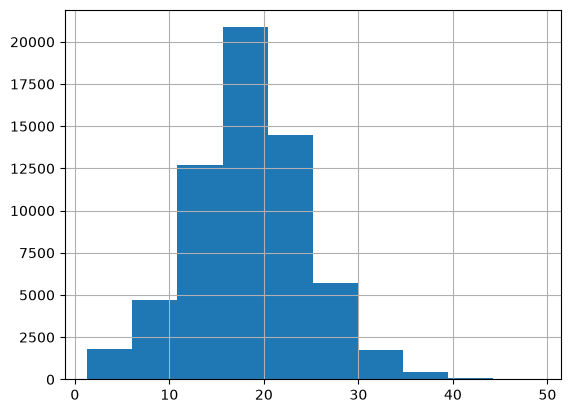

In [93]:
hgb_sd.hist()

In [94]:
np.percentile(hgb_sd, 1)

np.float64(3.5477184741863295)

In [95]:
# Some SDs are super super small! They make anemia not computable
hgb_sd = hgb_sd.clip(lower=np.percentile(hgb_sd, 1))

In [96]:
zero_fort_anemia = calculate_anemia_from_mean_sd_hemoglobin(
    hgb_mean_zero_fort.rename("mean"), hgb_sd
)
zero_fort_anemia

severe  moderate  \
sex    age_start age_end    wealth_quintile draw                           
Female 0.0       0.019178   1               draw_0    0.104861  0.475027   
                                            draw_1    0.220438  0.439420   
                                            draw_10   0.252519  0.469136   
                                            draw_100  0.121692  0.498225   
                                            draw_101  0.131948  0.485146   
...                                                        ...       ...   
Male   95.0      125.000000 5               draw_95   0.010388  0.361306   
                                            draw_96   0.007049  0.116132   
                                            draw_97   0.000681  0.067595   
                                            draw_98   0.000230  0.051723   
                                            draw_99   0.010367  0.351894   

                                                          mild    anemic  
sex    age_start age_end    wealth_quintile draw                          
Female 0.0       0.019178   1               draw_0    0.200359  0.780247  
                                            draw_1    0.145879  0.805737  
                                            draw_10   0.137299  0.858955  
                                            draw_100  0.193301  0.813218  
                                            draw_101  0.186436  0.803530  
...                                                        ...       ...  
Male   95.0      125.000000 5               draw_95   0.578855  0.950549  
                                            draw_96   0.390080  0.513261  
                                            draw_97   0.670960  0.739236  
                                            draw_98   0.784273  0.836226  
                                            draw_99   0.582367  0.944628  

[62500 rows x 4 columns]

In [97]:
with_baseline_fort_anemia = calculate_anemia_from_mean_sd_hemoglobin(
    hgb_mean_with_baseline_fortification.rename("mean"), hgb_sd
)
with_baseline_fort_anemia

severe  moderate  \
sex    age_start age_end    wealth_quintile draw                           
Female 0.0       0.019178   1               draw_0    0.104861  0.475027   
                                            draw_1    0.220438  0.439420   
                                            draw_10   0.252519  0.469136   
                                            draw_100  0.121692  0.498225   
                                            draw_101  0.131948  0.485146   
...                                                        ...       ...   
Male   95.0      125.000000 5               draw_95   0.010388  0.361306   
                                            draw_96   0.007049  0.116132   
                                            draw_97   0.000681  0.067595   
                                            draw_98   0.000230  0.051723   
                                            draw_99   0.010367  0.351894   

                                                          mild    anemic  
sex    age_start age_end    wealth_quintile draw                          
Female 0.0       0.019178   1               draw_0    0.200359  0.780247  
                                            draw_1    0.145879  0.805737  
                                            draw_10   0.137299  0.858955  
                                            draw_100  0.193301  0.813218  
                                            draw_101  0.186436  0.803530  
...                                                        ...       ...  
Male   95.0      125.000000 5               draw_95   0.578855  0.950549  
                                            draw_96   0.390080  0.513261  
                                            draw_97   0.670960  0.739236  
                                            draw_98   0.784273  0.836226  
                                            draw_99   0.582367  0.944628  

[62500 rows x 4 columns]

In [98]:
with_intervention_fort_anemia = calculate_anemia_from_mean_sd_hemoglobin(
    hgb_mean_with_intervention_fortification.rename("mean"), hgb_sd
)
with_intervention_fort_anemia

severe  \
sex    age_start age_end    wealth_quintile draw     scenario                 
Female 0.0       0.019178   1               draw_0   intervention  0.104861   
                                            draw_1   intervention  0.220438   
                                            draw_10  intervention  0.252519   
                                            draw_100 intervention  0.121692   
                                            draw_101 intervention  0.131948   
...                                                                     ...   
Male   95.0      125.000000 5               draw_95  intervention  0.010388   
                                            draw_96  intervention  0.007049   
                                            draw_97  intervention  0.000681   
                                            draw_98  intervention  0.000230   
                                            draw_99  intervention  0.010367   

                                                                   moderate  \
sex    age_start age_end    wealth_quintile draw     scenario                 
Female 0.0       0.019178   1               draw_0   intervention  0.475027   
                                            draw_1   intervention  0.439420   
                                            draw_10  intervention  0.469136   
                                            draw_100 intervention  0.498225   
                                            draw_101 intervention  0.485146   
...                                                                     ...   
Male   95.0      125.000000 5               draw_95  intervention  0.361306   
                                            draw_96  intervention  0.116132   
                                            draw_97  intervention  0.067595   
                                            draw_98  intervention  0.051723   
                                            draw_99  intervention  0.351894   

                                                                       mild  \
sex    age_start age_end    wealth_quintile draw     scenario                 
Female 0.0       0.019178   1               draw_0   intervention  0.200359   
                                            draw_1   intervention  0.145879   
                                            draw_10  intervention  0.137299   
                                            draw_100 intervention  0.193301   
                                            draw_101 intervention  0.186436   
...                                                                     ...   
Male   95.0      125.000000 5               draw_95  intervention  0.578855   
                                            draw_96  intervention  0.390080   
                                            draw_97  intervention  0.670960   
                                            draw_98  intervention  0.784273   
                                            draw_99  intervention  0.582367   

                                                                     anemic  
sex    age_start age_end    wealth_quintile draw     scenario                
Female 0.0       0.019178   1               draw_0   intervention  0.780247  
                                            draw_1   intervention  0.805737  
                                            draw_10  intervention  0.858955  
                                            draw_100 intervention  0.813218  
                                            draw_101 intervention  0.803530  
...                                                                     ...  
Male   95.0      125.000000 5               draw_95  intervention  0.950549  
                                            draw_96  intervention  0.513261  
                                            draw_97  intervention  0.739236  
                                            draw_98  intervention  0.836226  
                                            draw_

In [99]:
total_population_anemia = calculate_anemia_from_mean_sd_hemoglobin(hgb_mean, hgb_sd)
total_population_anemia

severe  moderate  \
sex    age_start age_end    wealth_quintile draw                           
Female 0.0       0.019178   1               draw_0    0.104861  0.475027   
                                            draw_1    0.220438  0.439420   
                                            draw_10   0.252519  0.469136   
                                            draw_100  0.121692  0.498225   
                                            draw_101  0.131948  0.485146   
...                                                        ...       ...   
Male   95.0      125.000000 5               draw_95   0.010388  0.361306   
                                            draw_96   0.007049  0.116132   
                                            draw_97   0.000681  0.067595   
                                            draw_98   0.000230  0.051723   
                                            draw_99   0.010367  0.351894   

                                                          mild    anemic  
sex    age_start age_end    wealth_quintile draw                          
Female 0.0       0.019178   1               draw_0    0.200359  0.780247  
                                            draw_1    0.145879  0.805737  
                                            draw_10   0.137299  0.858955  
                                            draw_100  0.193301  0.813218  
                                            draw_101  0.186436  0.803530  
...                                                        ...       ...  
Male   95.0      125.000000 5               draw_95   0.578855  0.950549  
                                            draw_96   0.390080  0.513261  
                                            draw_97   0.670960  0.739236  
                                            draw_98   0.784273  0.836226  
                                            draw_99   0.582367  0.944628  

[62500 rows x 4 columns]

In [100]:
# NOTE: Here, we assume everyone is folate-responsive, instead of splitting this effect into
# a bigger effect among the folate-responsive and 0 among the non-

In [101]:
baseline_anemia = zero_fort_anemia.mul(
    (1 - effective_coverage_baseline), axis=0
) + with_baseline_fort_anemia.mul(
    effective_coverage_baseline, axis=0
)
baseline_anemia

severe  moderate  \
sex    age_start age_end    wealth_quintile draw                           
Female 0.0       0.019178   1               draw_0    0.104861  0.475027   
                                            draw_1    0.220438  0.439420   
                                            draw_10   0.252519  0.469136   
                                            draw_100  0.121692  0.498225   
                                            draw_101  0.131948  0.485146   
...                                                        ...       ...   
Male   95.0      125.000000 5               draw_95   0.010388  0.361306   
                                            draw_96   0.007049  0.116132   
                                            draw_97   0.000681  0.067595   
                                            draw_98   0.000230  0.051723   
                                            draw_99   0.010367  0.351894   

                                                          mild    anemic  
sex    age_start age_end    wealth_quintile draw                          
Female 0.0       0.019178   1               draw_0    0.200359  0.780247  
                                            draw_1    0.145879  0.805737  
                                            draw_10   0.137299  0.858955  
                                            draw_100  0.193301  0.813218  
                                            draw_101  0.186436  0.803530  
...                                                        ...       ...  
Male   95.0      125.000000 5               draw_95   0.578855  0.950549  
                                            draw_96   0.390080  0.513261  
                                            draw_97   0.670960  0.739236  
                                            draw_98   0.784273  0.836226  
                                            draw_99   0.582367  0.944628  

[62500 rows x 4 columns]

In [102]:
(baseline_anemia - total_population_anemia).describe()

,severe,moderate,mild,anemic
count,6.250000e+04,62500.000000,62500.000000,6.250000e+04
mean,6.883994e-06,0.000033,0.000002,4.177458e-05
std,2.513492e-05,0.000094,0.000038,1.023839e-04
min,-2.775558e-17,-0.000025,-0.000817,-1.110223e-16
25%,0.000000e+00,0.000000,0.000000,0.000000e+00
50%,0.000000e+00,0.000000,0.000000,0.000000e+00
75%,7.494272e-07,0.000011,0.000000,2.531662e-05
max,2.253912e-04,0.001426,0.001268,1.761177e-03


In [103]:
(
    baseline_anemia.loc[example_tuple].mean()
    - with_intervention_fort_anemia.loc[example_tuple].mean()
) / baseline_anemia.loc[example_tuple].mean()

severe      0.253260
moderate    0.209070
mild        0.117685
anemic      0.177424
dtype: float64

In [104]:
zero_fort_anemia

severe  moderate  \
sex    age_start age_end    wealth_quintile draw                           
Female 0.0       0.019178   1               draw_0    0.104861  0.475027   
                                            draw_1    0.220438  0.439420   
                                            draw_10   0.252519  0.469136   
                                            draw_100  0.121692  0.498225   
                                            draw_101  0.131948  0.485146   
...                                                        ...       ...   
Male   95.0      125.000000 5               draw_95   0.010388  0.361306   
                                            draw_96   0.007049  0.116132   
                                            draw_97   0.000681  0.067595   
                                            draw_98   0.000230  0.051723   
                                            draw_99   0.010367  0.351894   

                                                          mild    anemic  
sex    age_start age_end    wealth_quintile draw                          
Female 0.0       0.019178   1               draw_0    0.200359  0.780247  
                                            draw_1    0.145879  0.805737  
                                            draw_10   0.137299  0.858955  
                                            draw_100  0.193301  0.813218  
                                            draw_101  0.186436  0.803530  
...                                                        ...       ...  
Male   95.0      125.000000 5               draw_95   0.578855  0.950549  
                                            draw_96   0.390080  0.513261  
                                            draw_97   0.670960  0.739236  
                                            draw_98   0.784273  0.836226  
                                            draw_99   0.582367  0.944628  

[62500 rows x 4 columns]

In [105]:
intervention_anemia = zero_fort_anemia.mul(
    (1 - effective_coverage_intervention),
    axis=0,
) + with_intervention_fort_anemia.mul(effective_coverage_intervention, axis=0)
intervention_anemia

severe  \
sex    age_start age_end    wealth_quintile draw     scenario                 
Female 0.0       0.019178   1               draw_0   intervention  0.104861   
                                            draw_1   intervention  0.220438   
                                            draw_10  intervention  0.252519   
                                            draw_100 intervention  0.121692   
                                            draw_101 intervention  0.131948   
...                                                                     ...   
Male   95.0      125.000000 5               draw_95  intervention  0.010388   
                                            draw_96  intervention  0.007049   
                                            draw_97  intervention  0.000681   
                                            draw_98  intervention  0.000230   
                                            draw_99  intervention  0.010367   

                                                                   moderate  \
sex    age_start age_end    wealth_quintile draw     scenario                 
Female 0.0       0.019178   1               draw_0   intervention  0.475027   
                                            draw_1   intervention  0.439420   
                                            draw_10  intervention  0.469136   
                                            draw_100 intervention  0.498225   
                                            draw_101 intervention  0.485146   
...                                                                     ...   
Male   95.0      125.000000 5               draw_95  intervention  0.361306   
                                            draw_96  intervention  0.116132   
                                            draw_97  intervention  0.067595   
                                            draw_98  intervention  0.051723   
                                            draw_99  intervention  0.351894   

                                                                       mild  \
sex    age_start age_end    wealth_quintile draw     scenario                 
Female 0.0       0.019178   1               draw_0   intervention  0.200359   
                                            draw_1   intervention  0.145879   
                                            draw_10  intervention  0.137299   
                                            draw_100 intervention  0.193301   
                                            draw_101 intervention  0.186436   
...                                                                     ...   
Male   95.0      125.000000 5               draw_95  intervention  0.578855   
                                            draw_96  intervention  0.390080   
                                            draw_97  intervention  0.670960   
                                            draw_98  intervention  0.784273   
                                            draw_99  intervention  0.582367   

                                                                     anemic  
sex    age_start age_end    wealth_quintile draw     scenario                
Female 0.0       0.019178   1               draw_0   intervention  0.780247  
                                            draw_1   intervention  0.805737  
                                            draw_10  intervention  0.858955  
                                            draw_100 intervention  0.813218  
                                            draw_101 intervention  0.803530  
...                                                                     ...  
Male   95.0      125.000000 5               draw_95  intervention  0.950549  
                                            draw_96  intervention  0.513261  
                                            draw_97  intervention  0.739236  
                                            draw_98  intervention  0.836226  
                                            draw_

In [106]:
from lsff_utils.hemoglobin_distribution import hemoglobin_pdf_from_mean_sd

In [107]:
total_population_pdf = hemoglobin_pdf_from_mean_sd(
    np.array([hgb_mean.loc[example_tuple].mean()]),
    np.array([hgb_sd.loc[example_tuple].mean()]),
)
total_population_pdf

<function lsff_utils.hemoglobin_distribution.hemoglobin_pdf_from_mean_sd.<locals>.pdf(x)>

In [108]:
zero_fort_pdf = hemoglobin_pdf_from_mean_sd(
    np.array([hgb_mean_zero_fort.loc[example_tuple].mean()]),
    np.array([hgb_sd.loc[example_tuple].mean()]),
)
zero_fort_pdf

<function lsff_utils.hemoglobin_distribution.hemoglobin_pdf_from_mean_sd.<locals>.pdf(x)>

In [109]:
with_baseline_fort_pdf = hemoglobin_pdf_from_mean_sd(
    np.array([hgb_mean_with_baseline_fortification.loc[example_tuple].mean()]),
    np.array([hgb_sd.loc[example_tuple].mean()]),
)
with_baseline_fort_pdf

<function lsff_utils.hemoglobin_distribution.hemoglobin_pdf_from_mean_sd.<locals>.pdf(x)>

In [110]:
with_intervention_fort_pdf = hemoglobin_pdf_from_mean_sd(
    np.array([hgb_mean_with_intervention_fortification.loc[example_tuple].mean()]),
    np.array([hgb_sd.loc[example_tuple].mean()]),
)
with_intervention_fort_pdf

<function lsff_utils.hemoglobin_distribution.hemoglobin_pdf_from_mean_sd.<locals>.pdf(x)>

In [111]:
def baseline_pdf(x):
    effective_covered = effective_coverage_baseline.loc[example_tuple]
    return (
        zero_fort_pdf(x) * (1 - effective_covered)
        + with_baseline_fort_pdf(x) * effective_covered
    )

In [112]:
def intervention_pdf(x):
    effective_covered = effective_coverage_intervention.loc[example_tuple]
    return (
        zero_fort_pdf(x) * (1 - effective_covered)
        + with_intervention_fort_pdf(x) * effective_covered
    )

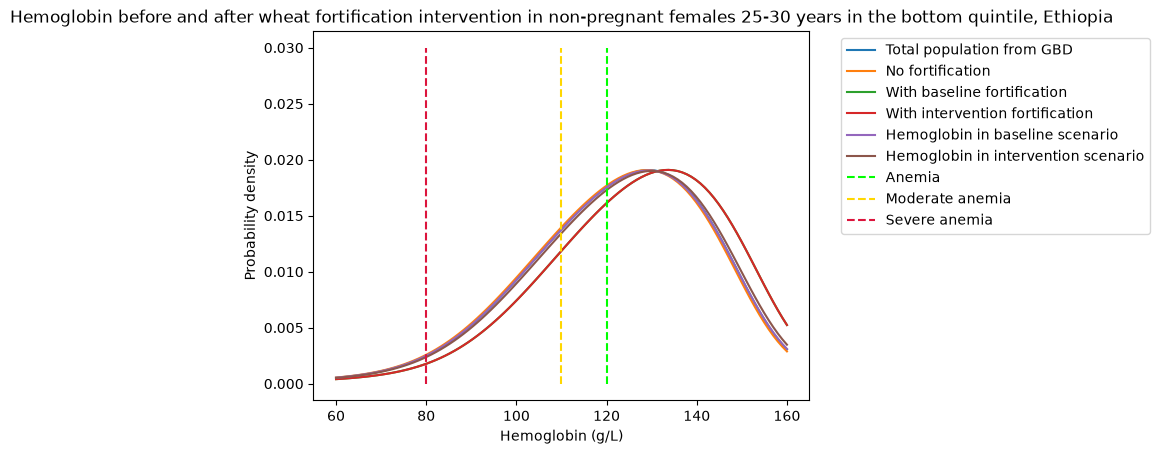

In [113]:
import matplotlib.pyplot as plt

x_values = np.linspace(60, 160, 100)
with np.errstate(under="ignore"):
    plt.plot(
        x_values,
        [total_population_pdf(x) for x in x_values],
        label="Total population from GBD",
    )
    plt.plot(
        x_values,
        [zero_fort_pdf(x) for x in x_values],
        label="No fortification",
    )
    plt.plot(
        x_values,
        [with_baseline_fort_pdf(x) for x in x_values],
        label="With baseline fortification",
    )
    plt.plot(
        x_values,
        [with_intervention_fort_pdf(x) for x in x_values],
        label="With intervention fortification",
    )
    plt.plot(
        x_values,
        [baseline_pdf(x) for x in x_values],
        label="Hemoglobin in baseline scenario",
    )
    plt.plot(
        x_values,
        [intervention_pdf(x) for x in x_values],
        label="Hemoglobin in intervention scenario",
    )
    plt.vlines(
        thresholds.loc[
            (example_sex, example_age_start, example_age_end, 0)
        ].hgb_upper_mild,
        0,
        0.03,
        linestyles="dashed",
        label="Anemia",
        color="lime",
    )
    plt.vlines(
        thresholds.loc[
            (example_sex, example_age_start, example_age_end, 0)
        ].hgb_upper_moderate,
        0,
        0.03,
        linestyles="dashed",
        label="Moderate anemia",
        color="gold",
    )
    plt.vlines(
        thresholds.loc[
            (example_sex, example_age_start, example_age_end, 0)
        ].hgb_upper_severe,
        0,
        0.03,
        linestyles="dashed",
        label="Severe anemia",
        color="crimson",
    )
    plt.xlabel("Hemoglobin (g/L)")
    plt.ylabel("Probability density")
    plt.title(
        f"Hemoglobin before and after {vehicle} fortification intervention in non-pregnant females 25-30 years in the bottom quintile, {location.title()}"
    )
    plt.legend(bbox_to_anchor=(1.05, 1))

In [114]:
(baseline_anemia - intervention_anemia).sort_values("anemic")

severe  \
sex    age_start age_end    wealth_quintile draw     scenario                     
Male   95.000000 125.000000 5               draw_98  intervention -2.710505e-20   
Female 0.019178  0.076712   3               draw_19  intervention  0.000000e+00   
                            4               draw_146 intervention  0.000000e+00   
Male   95.000000 125.000000 3               draw_152 intervention  0.000000e+00   
Female 0.076712  0.500000   2               draw_140 intervention  0.000000e+00   
...                                                                         ...   
       45.000000 50.000000  1               draw_1   intervention  2.739849e-04   
       40.000000 45.000000  1               draw_1   intervention  2.821858e-04   
       35.000000 40.000000  1               draw_10  intervention  4.621424e-04   
       40.000000 45.000000  1               draw_10  intervention  4.754315e-04   
Male   45.000000 50.000000  1               draw_211 intervention  3.723608e-05   

                                                                       moderate  \
sex    age_start age_end    wealth_quintile draw     scenario                     
Male   95.000000 125.000000 5               draw_98  intervention  6.938894e-18   
Female 0.019178  0.076712   3               draw_19  intervention  0.000000e+00   
                            4               draw_146 intervention  0.000000e+00   
Male   95.000000 125.000000 3               draw_152 intervention  0.000000e+00   
Female 0.076712  0.500000   2               draw_140 intervention  0.000000e+00   
...                                                                         ...   
       45.000000 50.000000  1               draw_1   intervention  1.211945e-02   
       40.000000 45.000000  1               draw_1   intervention  1.232687e-02   
       35.000000 40.000000  1               draw_10  intervention  1.457665e-02   
       40.000000 45.000000  1               draw_10  intervention  1.491024e-02   
Male   45.000000 50.000000  1               draw_211 intervention  2.136158e-03   

                                                                       mild  \
sex    age_start age_end    wealth_quintile draw     scenario                 
Male   95.000000 125.000000 5               draw_98  intervention  0.000000   
Female 0.019178  0.076712   3               draw_19  intervention  0.000000   
                            4               draw_146 intervention  0.000000   
Male   95.000000 125.000000 3               draw_152 intervention  0.000000   
Female 0.076712  0.500000   2               draw_140 intervention  0.000000   
...                                                                     ...   
       45.000000 50.000000  1               draw_1   intervention  0.011310   
       40.000000 45.000000  1               draw_1   intervention  0.011215   
       35.000000 40.000000  1               draw_10  intervention  0.008900   
       40.000000 45.000000  1               draw_10  intervention  0.008773   
Male   45.000000 50.000000  1               draw_211 intervention  0.022105   

                                                                         anemic  
sex    age_start age_end    wealth_quintile draw     scenario                    
Male   95.000000 125.000000 5               draw_98  intervention -2.220446e-16  
Female 0.019178  0.076712   3               draw_19  intervention -2.220446e-16  
                            4               draw_146 intervention -2.220446e-16  
Male   95.000000 125.000000 3               draw_152 intervention -2.220446e-16  
Female 0.076712  0.500000   2               draw_140 intervention -2.220446e-16  
...                                                                         ...  
       45.000000 50.000000  1               draw_1   intervention  2.370318e-02  
       40.000000 45.000000  1               draw_1   intervention  2.382398e-02  
       35.000000 40.000000  1               draw_10  intervention

In [115]:
def anemia_to_yld_rates(anemia):
    disability_weights = pd.read_hdf(
        "/mnt/team/simulation_science/costeffectiveness/auxiliary_data/GBD_2021/02_processed_data/disability_weight/sequela/all/all.hdf"
    )
    disability_weights = (
        disability_weights[
            disability_weights.healthstate.isin(
                ["anemia_mild", "anemia_mod", "anemia_sev"]
            )
        ]
        .set_index("healthstate")
        .filter(like="draw_")
    )
    disability_weights.columns.name = "draw"
    disability_weights = (
        disability_weights.stack().rename("disability_weight").reset_index()
    )
    display(disability_weights)

    orig_index = anemia.index
    anemia = (
        anemia.reset_index()
        .merge(
            disability_weights[disability_weights.healthstate == "anemia_mild"][
                ["draw", "disability_weight"]
            ].rename(columns={"disability_weight": "mild_dw"}),
            validate="m:1",
        )
        .merge(
            disability_weights[disability_weights.healthstate == "anemia_mod"][
                ["draw", "disability_weight"]
            ].rename(columns={"disability_weight": "moderate_dw"}),
            validate="m:1",
        )
        .merge(
            disability_weights[disability_weights.healthstate == "anemia_sev"][
                ["draw", "disability_weight"]
            ].rename(columns={"disability_weight": "severe_dw"}),
            validate="m:1",
        )
    )

    anemia["mild_yld_rate"] = anemia.mild * anemia.mild_dw
    anemia["moderate_yld_rate"] = anemia.moderate * anemia.moderate_dw
    anemia["severe_yld_rate"] = anemia.severe * anemia.severe_dw
    anemia["anemic_yld_rate"] = (
        anemia["mild_yld_rate"]
        + anemia["moderate_yld_rate"]
        + anemia["severe_yld_rate"]
    )

    return anemia.set_index(orig_index.names).filter(like="yld_rate")

In [116]:
zero_fort_anemia_yld_rates = anemia_to_yld_rates(zero_fort_anemia)
zero_fort_anemia_yld_rates

,healthstate,draw,disability_weight
0,anemia_mild,draw_0,0.002420
1,anemia_mild,draw_1,0.003172
2,anemia_mild,draw_2,0.002644
3,anemia_mild,draw_3,0.003085
4,anemia_mild,draw_4,0.001845
...,...,...,...
2995,anemia_sev,draw_995,0.174969
2996,anemia_sev,draw_996,0.086798
2997,anemia_sev,draw_997,0.131996
2998,anemia_sev,draw_998,0.124427


mild_yld_rate  \
sex    age_start age_end    wealth_quintile draw                      
Female 0.0       0.019178   1               draw_0         0.000485   
                                            draw_1         0.000463   
                                            draw_10        0.000472   
                                            draw_100       0.000714   
                                            draw_101       0.000380   
...                                                             ...   
Male   95.0      125.000000 5               draw_95        0.003268   
                                            draw_96        0.002053   
                                            draw_97        0.001872   
                                            draw_98        0.003069   
                                            draw_99        0.002446   

                                                      moderate_yld_rate  \
sex    age_start age_end    wealth_quintile draw                          
Female 0.0       0.019178   1               draw_0             0.028169   
                                            draw_1             0.025078   
                                            draw_10            0.020746   
                                            draw_100           0.027958   
                                            draw_101           0.021502   
...                                                                 ...   
Male   95.0      125.000000 5               draw_95            0.023616   
                                            draw_96            0.005721   
                                            draw_97            0.004010   
                                            draw_98            0.001988   
                                            draw_99            0.014667   

                                                      severe_yld_rate  \
sex    age_start age_end    wealth_quintile draw                        
Female 0.0       0.019178   1               draw_0           0.020861   
                                            draw_1           0.035368   
                                            draw_10          0.035342   
                                            draw_100         0.021204   
                                            draw_101         0.021278   
...                                                               ...   
Male   95.0      125.000000 5               draw_95          0.001772   
                                            draw_96          0.000990   
                                            draw_97          0.000136   
                                            draw_98          0.000021   
                                            draw_99          0.001231   

                                                      anemic_yld_rate  
sex    age_start age_end    wealth_quintile draw                       
Female 0.0       0.019178   1               draw_0           0.049515  
                                            draw_1           0.060908  
                                            draw_10          0.056560  
                                            draw_100         0.049877  
                                            draw_101         0.043160  
...                                                               ...  
Male   95.0      125.000000 5               draw_95          0.028656  
                                            draw_96          0.008764  
                                            draw_97          0.006018  
                                            draw_98          0.005077  
                                            draw_99          0.018345  

[62500 rows x 4 columns]

In [117]:
baseline_anemia_yld_rates = anemia_to_yld_rates(baseline_anemia)
baseline_anemia_yld_rates

,healthstate,draw,disability_weight
0,anemia_mild,draw_0,0.002420
1,anemia_mild,draw_1,0.003172
2,anemia_mild,draw_2,0.002644
3,anemia_mild,draw_3,0.003085
4,anemia_mild,draw_4,0.001845
...,...,...,...
2995,anemia_sev,draw_995,0.174969
2996,anemia_sev,draw_996,0.086798
2997,anemia_sev,draw_997,0.131996
2998,anemia_sev,draw_998,0.124427


mild_yld_rate  \
sex    age_start age_end    wealth_quintile draw                      
Female 0.0       0.019178   1               draw_0         0.000485   
                                            draw_1         0.000463   
                                            draw_10        0.000472   
                                            draw_100       0.000714   
                                            draw_101       0.000380   
...                                                             ...   
Male   95.0      125.000000 5               draw_95        0.003268   
                                            draw_96        0.002053   
                                            draw_97        0.001872   
                                            draw_98        0.003069   
                                            draw_99        0.002446   

                                                      moderate_yld_rate  \
sex    age_start age_end    wealth_quintile draw                          
Female 0.0       0.019178   1               draw_0             0.028169   
                                            draw_1             0.025078   
                                            draw_10            0.020746   
                                            draw_100           0.027958   
                                            draw_101           0.021502   
...                                                                 ...   
Male   95.0      125.000000 5               draw_95            0.023616   
                                            draw_96            0.005721   
                                            draw_97            0.004010   
                                            draw_98            0.001988   
                                            draw_99            0.014667   

                                                      severe_yld_rate  \
sex    age_start age_end    wealth_quintile draw                        
Female 0.0       0.019178   1               draw_0           0.020861   
                                            draw_1           0.035368   
                                            draw_10          0.035342   
                                            draw_100         0.021204   
                                            draw_101         0.021278   
...                                                               ...   
Male   95.0      125.000000 5               draw_95          0.001772   
                                            draw_96          0.000990   
                                            draw_97          0.000136   
                                            draw_98          0.000021   
                                            draw_99          0.001231   

                                                      anemic_yld_rate  
sex    age_start age_end    wealth_quintile draw                       
Female 0.0       0.019178   1               draw_0           0.049515  
                                            draw_1           0.060908  
                                            draw_10          0.056560  
                                            draw_100         0.049877  
                                            draw_101         0.043160  
...                                                               ...  
Male   95.0      125.000000 5               draw_95          0.028656  
                                            draw_96          0.008764  
                                            draw_97          0.006018  
                                            draw_98          0.005077  
                                            draw_99          0.018345  

[62500 rows x 4 columns]

In [118]:
(
    baseline_anemia_yld_rates.loc[("Female", 25, 30, 1)].mean()
    - anemia_to_yld_rates(with_intervention_fort_anemia).loc[("Female", 25, 30, 1)].mean()
) / baseline_anemia_yld_rates.loc[("Female", 25, 30, 1)].mean()

,healthstate,draw,disability_weight
0,anemia_mild,draw_0,0.002420
1,anemia_mild,draw_1,0.003172
2,anemia_mild,draw_2,0.002644
3,anemia_mild,draw_3,0.003085
4,anemia_mild,draw_4,0.001845
...,...,...,...
2995,anemia_sev,draw_995,0.174969
2996,anemia_sev,draw_996,0.086798
2997,anemia_sev,draw_997,0.131996
2998,anemia_sev,draw_998,0.124427


mild_yld_rate        0.118455
moderate_yld_rate    0.208985
severe_yld_rate      0.253062
anemic_yld_rate      0.219093
dtype: float64

In [119]:
intervention_anemia_yld_rates = anemia_to_yld_rates(intervention_anemia)
intervention_anemia_yld_rates

,healthstate,draw,disability_weight
0,anemia_mild,draw_0,0.002420
1,anemia_mild,draw_1,0.003172
2,anemia_mild,draw_2,0.002644
3,anemia_mild,draw_3,0.003085
4,anemia_mild,draw_4,0.001845
...,...,...,...
2995,anemia_sev,draw_995,0.174969
2996,anemia_sev,draw_996,0.086798
2997,anemia_sev,draw_997,0.131996
2998,anemia_sev,draw_998,0.124427


mild_yld_rate  \
sex    age_start age_end    wealth_quintile draw     scenario                      
Female 0.0       0.019178   1               draw_0   intervention       0.000485   
                                            draw_1   intervention       0.000463   
                                            draw_10  intervention       0.000472   
                                            draw_100 intervention       0.000714   
                                            draw_101 intervention       0.000380   
...                                                                          ...   
Male   95.0      125.000000 5               draw_95  intervention       0.003268   
                                            draw_96  intervention       0.002053   
                                            draw_97  intervention       0.001872   
                                            draw_98  intervention       0.003069   
                                            draw_99  intervention       0.002446   

                                                                   moderate_yld_rate  \
sex    age_start age_end    wealth_quintile draw     scenario                          
Female 0.0       0.019178   1               draw_0   intervention           0.028169   
                                            draw_1   intervention           0.025078   
                                            draw_10  intervention           0.020746   
                                            draw_100 intervention           0.027958   
                                            draw_101 intervention           0.021502   
...                                                                              ...   
Male   95.0      125.000000 5               draw_95  intervention           0.023616   
                                            draw_96  intervention           0.005721   
                                            draw_97  intervention           0.004010   
                                            draw_98  intervention           0.001988   
                                            draw_99  intervention           0.014667   

                                                                   severe_yld_rate  \
sex    age_start age_end    wealth_quintile draw     scenario                        
Female 0.0       0.019178   1               draw_0   intervention         0.020861   
                                            draw_1   intervention         0.035368   
                                            draw_10  intervention         0.035342   
                                            draw_100 intervention         0.021204   
                                            draw_101 intervention         0.021278   
...                                                                            ...   
Male   95.0      125.000000 5               draw_95  intervention         0.001772   
                                            draw_96  intervention         0.000990   
                                            draw_97  intervention         0.000136   
                                            draw_98  intervention         0.000021   
                                            draw_99  intervention         0.001231   

                                                                   anemic_yld_rate  
sex    age_start age_end    wealth_quintile draw     scenario                       
Female 0.0       0.019178   1               draw_0   intervention         0.049515  
                                            draw_1   intervention         0.060908  
                                            draw_10  intervention         0.056560  
                                            draw_100 intervention         0.049877  
                                            draw_101 intervention         0.043160  
...                                                                            ...  
Male   95.0      125.000000 5 

In [120]:
(baseline_anemia_yld_rates - intervention_anemia_yld_rates).sort_values(
    "anemic_yld_rate"
)

mild_yld_rate  \
sex    age_start age_end    wealth_quintile draw     scenario                      
Female 0.000000  0.019178   1               draw_184 intervention       0.000000   
Male   0.076712  0.500000   3               draw_242 intervention       0.000000   
Female 1.000000  2.000000   1               draw_78  intervention       0.000000   
Male   0.500000  1.000000   2               draw_45  intervention       0.000000   
Female 95.000000 125.000000 3               draw_219 intervention       0.000000   
...                                                                          ...   
       45.000000 50.000000  1               draw_45  intervention       0.000035   
       40.000000 45.000000  1               draw_45  intervention       0.000033   
       35.000000 40.000000  1               draw_45  intervention       0.000035   
                                            draw_53  intervention       0.000070   
       40.000000 45.000000  1               draw_53  intervention       0.000071   

                                                                   moderate_yld_rate  \
sex    age_start age_end    wealth_quintile draw     scenario                          
Female 0.000000  0.019178   1               draw_184 intervention      -6.938894e-18   
Male   0.076712  0.500000   3               draw_242 intervention      -6.938894e-18   
Female 1.000000  2.000000   1               draw_78  intervention      -6.938894e-18   
Male   0.500000  1.000000   2               draw_45  intervention      -6.938894e-18   
Female 95.000000 125.000000 3               draw_219 intervention       0.000000e+00   
...                                                                              ...   
       45.000000 50.000000  1               draw_45  intervention       8.334269e-04   
       40.000000 45.000000  1               draw_45  intervention       8.340605e-04   
       35.000000 40.000000  1               draw_45  intervention       8.553360e-04   
                                            draw_53  intervention       1.084523e-03   
       40.000000 45.000000  1               draw_53  intervention       1.140405e-03   

                                                                   severe_yld_rate  \
sex    age_start age_end    wealth_quintile draw     scenario                        
Female 0.000000  0.019178   1               draw_184 intervention     0.000000e+00   
Male   0.076712  0.500000   3               draw_242 intervention     0.000000e+00   
Female 1.000000  2.000000   1               draw_78  intervention     0.000000e+00   
Male   0.500000  1.000000   2               draw_45  intervention     0.000000e+00   
Female 95.000000 125.000000 3               draw_219 intervention    -6.938894e-18   
...                                                                            ...   
       45.000000 50.000000  1               draw_45  intervention     2.862127e-04   
       40.000000 45.000000  1               draw_45  intervention     3.168171e-04   
       35.000000 40.000000  1               draw_45  intervention     3.049880e-04   
                                            draw_53  intervention     9.501803e-05   
       40.000000 45.000000  1               draw_53  intervention     9.441404e-05   

                                                                   anemic_yld_rate  
sex    age_start age_end    wealth_quintile draw     scenario                       
Female 0.000000  0.019178   1               draw_184 intervention    -1.387779e-17  
Male   0.076712  0.500000   3               draw_242 intervention    -1.387779e-17  
Female 1.000000  2.000000   1               draw_78  intervention    -1.387779e-17  
Male   0.500000  1.000000   2               draw_45  intervention    -1.387779e-17  
Female 95.000000 125.000000 3               draw_219 intervention    -1.387779e-17  
...                                                                            ...  
       45.000000 50.000000  1 

In [121]:
(baseline_anemia_yld_rates - intervention_anemia_yld_rates).anemic_yld_rate.describe()

count    6.250000e+04
mean     5.587002e-05
std      1.355884e-04
min     -1.387779e-17
25%      0.000000e+00
50%      0.000000e+00
75%      3.398256e-05
max      1.305618e-03
Name: anemic_yld_rate, dtype: float64

In [122]:
assert (
    ((baseline_anemia_yld_rates - intervention_anemia_yld_rates).anemic_yld_rate >= 0)
    | np.isclose(
        (baseline_anemia_yld_rates - intervention_anemia_yld_rates).anemic_yld_rate, 0
    )
).all()

In [123]:
zero_fort_ylds = (
    zero_fort_anemia_yld_rates.anemic_yld_rate.unstack("draw").mean(axis=1)
    * non_pregnant_pop
)
zero_fort_ylds

sex     age_start  age_end     wealth_quintile
Female  0.0        0.019178    1                  395.450077
                               2                  295.482645
                               3                  240.051599
                               4                  230.732019
                               5                  150.407217
                                                     ...    
Male    95.0       125.000000  1                   39.037013
                               2                   29.027163
                               3                   27.422539
                               4                   26.059157
                               5                   18.786956
Length: 250, dtype: float64

In [124]:
baseline_ylds = (
    baseline_anemia_yld_rates.anemic_yld_rate.unstack("draw").mean(axis=1)
    * non_pregnant_pop
)
baseline_ylds

sex     age_start  age_end     wealth_quintile
Female  0.0        0.019178    1                  395.450077
                               2                  295.482645
                               3                  240.051599
                               4                  230.732019
                               5                  150.407217
                                                     ...    
Male    95.0       125.000000  1                   39.037013
                               2                   29.027163
                               3                   27.422539
                               4                   26.059157
                               5                   18.786956
Length: 250, dtype: float64

In [125]:
intervention_ylds = (
    intervention_anemia_yld_rates.anemic_yld_rate.unstack("draw").mean(axis=1)
    * non_pregnant_pop
)
intervention_ylds

sex     age_start  age_end     wealth_quintile  scenario    
Female  0.0        0.019178    1                intervention    395.450077
                               2                intervention    295.482645
                               3                intervention    240.051599
                               4                intervention    230.732019
                               5                intervention    150.407217
                                                                   ...    
Male    95.0       125.000000  1                intervention     39.037013
                               2                intervention     29.027163
                               3                intervention     27.422539
                               4                intervention     26.059157
                               5                intervention     18.786956
Length: 250, dtype: float64

In [126]:
(
    baseline_ylds.loc[("Female", 25, 30, 1)]
    - intervention_ylds.loc[("Female", 25, 30, 1)]
)

scenario
intervention    404.804445
dtype: float64

In [127]:
(
    baseline_ylds.groupby(["wealth_quintile"]).sum()
    - intervention_ylds.groupby(["wealth_quintile", "scenario"]).sum()
)

wealth_quintile  scenario    
1                intervention    4068.758341
2                intervention    1868.760430
3                intervention    1579.582573
4                intervention     919.326287
5                intervention     735.312389
dtype: float64

In [128]:
ylds = pd.concat(
    [
        zero_fort_ylds.rename("value").reset_index().assign(scenario="zero"),
        baseline_ylds.rename("value").reset_index().assign(scenario="baseline"),
        intervention_ylds.rename("value").reset_index(),
    ],
    ignore_index=True,
)
ylds

,sex,age_start,age_end,wealth_quintile,value,scenario
0,Female,0.0,0.019178,1,395.450077,zero
1,Female,0.0,0.019178,2,295.482645,zero
2,Female,0.0,0.019178,3,240.051599,zero
3,Female,0.0,0.019178,4,230.732019,zero
4,Female,0.0,0.019178,5,150.407217,zero
...,...,...,...,...,...,...
745,Male,95.0,125.000000,1,39.037013,intervention
746,Male,95.0,125.000000,2,29.027163,intervention
747,Male,95.0,125.000000,3,27.422539,intervention
748,Male,95.0,125.000000,4,26.059157,intervention


In [129]:
results_dir = (
    paths.output_root(paths.NON_PREGNANT_ANEMIA_RESULTS_ROOT)
    / vehicle.lower()
    / location.lower()
)

In [130]:
path = f"{results_dir}/ylds.parquet"
pathlib.Path(path).parent.mkdir(exist_ok=True, parents=True)
ylds.to_parquet(path)

In [131]:
zero_fort_anemia_prevalence = zero_fort_anemia["anemic"].unstack("draw").mean(axis=1)
zero_fort_anemia_prevalence

sex     age_start  age_end     wealth_quintile
Female  0.0        0.019178    1                  0.799079
                               2                  0.776582
                               3                  0.727056
                               4                  0.785388
                               5                  0.707277
                                                    ...   
Male    95.0       125.000000  1                  0.881767
                               2                  0.871635
                               3                  0.864783
                               4                  0.857060
                               5                  0.839792
Length: 250, dtype: float64

In [132]:
baseline_anemia_prevalence = baseline_anemia["anemic"].unstack("draw").mean(axis=1)
baseline_anemia_prevalence

sex     age_start  age_end     wealth_quintile
Female  0.0        0.019178    1                  0.799079
                               2                  0.776582
                               3                  0.727056
                               4                  0.785388
                               5                  0.707277
                                                    ...   
Male    95.0       125.000000  1                  0.881767
                               2                  0.871635
                               3                  0.864783
                               4                  0.857060
                               5                  0.839792
Length: 250, dtype: float64

In [133]:
zero_fort_anemia_cases = zero_fort_anemia_prevalence.mul(non_pregnant_pop, axis=0)
zero_fort_anemia_cases

sex     age_start  age_end     wealth_quintile
Female  0.0        0.019178    1                  6481.050979
                               2                  5725.513365
                               3                  5067.651061
                               4                  4909.270640
                               5                  3543.680880
                                                     ...     
Male    95.0       125.000000  1                  1286.970457
                               2                  1331.050144
                               3                  1370.704637
                               4                  1437.374396
                               5                  1234.329289
Length: 250, dtype: float64

In [134]:
zero_fort_anemia_cases.sum() / non_pregnant_pop.sum()

np.float64(0.3257853378282317)

In [135]:
baseline_anemia_cases = baseline_anemia_prevalence.mul(non_pregnant_pop, axis=0)
baseline_anemia_cases

sex     age_start  age_end     wealth_quintile
Female  0.0        0.019178    1                  6481.050979
                               2                  5725.513365
                               3                  5067.651061
                               4                  4909.270640
                               5                  3543.680880
                                                     ...     
Male    95.0       125.000000  1                  1286.970457
                               2                  1331.050144
                               3                  1370.704637
                               4                  1437.374396
                               5                  1234.329289
Length: 250, dtype: float64

In [136]:
baseline_anemia_cases.sum() / non_pregnant_pop.sum()

np.float64(0.3243084530726512)

In [137]:
baseline_anemia_cases.groupby(["wealth_quintile"]).sum() / non_pregnant_pop.groupby(
    ["wealth_quintile"]
).sum()

wealth_quintile
1    0.448015
2    0.349864
3    0.309412
4    0.292746
5    0.230496
dtype: float64

In [138]:
intervention_anemia_prevalence = (
    intervention_anemia["anemic"].unstack("draw").mean(axis=1)
)
intervention_anemia_prevalence

sex     age_start  age_end     wealth_quintile  scenario    
Female  0.0        0.019178    1                intervention    0.799079
                               2                intervention    0.776582
                               3                intervention    0.727056
                               4                intervention    0.785388
                               5                intervention    0.707277
                                                                  ...   
Male    95.0       125.000000  1                intervention    0.881767
                               2                intervention    0.871635
                               3                intervention    0.864783
                               4                intervention    0.857060
                               5                intervention    0.839792
Length: 250, dtype: float64

In [139]:
total_population_anemia_prevalence = (
    total_population_anemia["anemic"].unstack("draw").mean(axis=1)
)
total_population_anemia_prevalence

sex     age_start  age_end     wealth_quintile
Female  0.0        0.019178    1                  0.799079
                               2                  0.776582
                               3                  0.727056
                               4                  0.785388
                               5                  0.707277
                                                    ...   
Male    95.0       125.000000  1                  0.881767
                               2                  0.871635
                               3                  0.864783
                               4                  0.857060
                               5                  0.839792
Length: 250, dtype: float64

In [140]:
total_population_anemia_cases = total_population_anemia_prevalence.mul(
    non_pregnant_pop, axis=0
)
total_population_anemia_cases

sex     age_start  age_end     wealth_quintile
Female  0.0        0.019178    1                  6481.050979
                               2                  5725.513365
                               3                  5067.651061
                               4                  4909.270640
                               5                  3543.680880
                                                     ...     
Male    95.0       125.000000  1                  1286.970457
                               2                  1331.050144
                               3                  1370.704637
                               4                  1437.374396
                               5                  1234.329289
Length: 250, dtype: float64

In [141]:
total_population_anemia_cases.sum() / non_pregnant_pop.sum()

np.float64(0.3242449745670216)

In [142]:
anemia_prevalence = pd.concat(
    [
        zero_fort_anemia_prevalence.rename("value")
        .reset_index()
        .assign(scenario="zero"),
        baseline_anemia_prevalence.rename("value")
        .reset_index()
        .assign(scenario="baseline"),
        intervention_anemia_prevalence.rename("value").reset_index(),
    ],
    ignore_index=True,
)
anemia_prevalence

,sex,age_start,age_end,wealth_quintile,value,scenario
0,Female,0.0,0.019178,1,0.799079,zero
1,Female,0.0,0.019178,2,0.776582,zero
2,Female,0.0,0.019178,3,0.727056,zero
3,Female,0.0,0.019178,4,0.785388,zero
4,Female,0.0,0.019178,5,0.707277,zero
...,...,...,...,...,...,...
745,Male,95.0,125.000000,1,0.881767,intervention
746,Male,95.0,125.000000,2,0.871635,intervention
747,Male,95.0,125.000000,3,0.864783,intervention
748,Male,95.0,125.000000,4,0.857060,intervention


In [143]:
path = f"{results_dir}/anemia_prevalence.parquet"
pathlib.Path(path).parent.mkdir(exist_ok=True, parents=True)
anemia_prevalence.to_parquet(path)

In [144]:
intervention_anemia_cases = intervention_anemia_prevalence.mul(non_pregnant_pop, axis=0)
intervention_anemia_cases

sex     age_start  age_end     wealth_quintile  scenario    
Female  0.0        0.019178    1                intervention    6481.050979
                               2                intervention    5725.513365
                               3                intervention    5067.651061
                               4                intervention    4909.270640
                               5                intervention    3543.680880
                                                                   ...     
Male    95.0       125.000000  1                intervention    1286.970457
                               2                intervention    1331.050144
                               3                intervention    1370.704637
                               4                intervention    1437.374396
                               5                intervention    1234.329289
Length: 250, dtype: float64

In [145]:
intervention_anemia_cases.groupby("scenario").sum() / non_pregnant_pop.sum()

scenario
intervention    0.321848
dtype: float64

In [146]:
intervention_anemia_cases.groupby(
    ["scenario", "wealth_quintile"]
).sum() / non_pregnant_pop.groupby(["wealth_quintile"]).sum()

scenario      wealth_quintile
intervention  1                  0.443409
              2                  0.347149
              3                  0.307011
              4                  0.291281
              5                  0.229244
dtype: float64

In [147]:
(
    baseline_anemia_cases.groupby(["wealth_quintile"]).sum()
    - intervention_anemia_cases.groupby(["scenario", "wealth_quintile"]).sum()
).map(lambda x: f"{round(x):,.0f}")

scenario      wealth_quintile
intervention  1                  97,187
              2                  58,270
              3                  51,986
              4                  32,286
              5                  28,575
dtype: str

In [148]:
anemia_cases = pd.concat(
    [
        zero_fort_anemia_cases.rename("value").reset_index().assign(scenario="zero"),
        baseline_anemia_cases.rename("value").reset_index().assign(scenario="baseline"),
        intervention_anemia_cases.rename("value").reset_index(),
    ],
    ignore_index=True,
)
anemia_cases

,sex,age_start,age_end,wealth_quintile,value,scenario
0,Female,0.0,0.019178,1,6481.050979,zero
1,Female,0.0,0.019178,2,5725.513365,zero
2,Female,0.0,0.019178,3,5067.651061,zero
3,Female,0.0,0.019178,4,4909.270640,zero
4,Female,0.0,0.019178,5,3543.680880,zero
...,...,...,...,...,...,...
745,Male,95.0,125.000000,1,1286.970457,intervention
746,Male,95.0,125.000000,2,1331.050144,intervention
747,Male,95.0,125.000000,3,1370.704637,intervention
748,Male,95.0,125.000000,4,1437.374396,intervention


In [149]:
path = f"{results_dir}/anemia_cases.parquet"
pathlib.Path(path).parent.mkdir(exist_ok=True, parents=True)
anemia_cases.to_parquet(path)

In [150]:
anemia_cases.notnull().all()

sex                True
age_start          True
age_end            True
wealth_quintile    True
value              True
scenario           True
dtype: bool